# Transfer Learning em Segmentação de Instâncias — HRSID

Segundo estudo do projeto, independente do experimento DeepPCB. Aqui o objetivo é detectar **e segmentar** navios em imagens SAR do HRSID com o Mask R-CNN ResNet-50 FPN V2 oficial do TorchVision, partindo dos pesos COCO.

## 1. Objetivos e modelo

- Reaproveitar um modelo treinado em fotografias naturais (COCO) para um domínio diferente: radar de abertura sintética, em tons de cinza, visto de cima.
- Medir detecção (caixas) e segmentação (máscaras) separadamente, no protocolo COCO.
- Treinar uma estratégia de transferência por rodada, escolhida em `CONFIG['experiment']`: backbone congelado, fine-tuning parcial ou fine-tuning completo.

O modelo é o [`maskrcnn_resnet50_fpn_v2`](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.detection.maskrcnn_resnet50_fpn_v2.html) com os pesos `MaskRCNN_ResNet50_FPN_V2_Weights.COCO_V1`. As cabeças de classificação e de máscara são trocadas por versões com duas classes: `0` fundo e `1` navio. O restante da rede — backbone, FPN, RPN e RoI Align — continua com os pesos do COCO.

O dataset fica **somente no Google Drive**: o notebook lê o `HRSID_jpg.zip` já existente, extrai uma única vez para uma pasta ao lado dele e nunca copia imagens para o repositório.

## 2. Ambiente

`CONFIG` reúne os parâmetros da rodada. A célula seguinte detecta o ambiente e, no Colab, monta o Drive e instala apenas os pacotes ausentes — o runtime do Colab já traz PyTorch e TorchVision, que não devem ser reinstalados. Depois vêm as importações, a semente e o dispositivo.

Localmente, instale as bibliotecas antes de abrir o notebook: `uv sync --extra cpu` para CPU ou `uv run python scripts/setup_gpu.py` para GPU. Não há dependência nova em relação ao experimento DeepPCB.

In [8]:
# Parâmetros da rodada. Ajuste aqui e reexecute esta célula antes de treinar.
# batch_size e num_workers só valem depois de recriar os DataLoaders (seção 8).
CONFIG = {
    'seed': 42,
    'experiment': 'frozen_backbone',   # frozen_backbone | partial_finetune | full_finetune
    'trainable_layers': 2,             # partial_finetune: blocos finais do ResNet-50 liberados (1 a 4)
    'epochs': 15,
    'patience': 5,
    'batch_size': 2,
    'num_workers': 2,
    'amp': True,                       # precisão mista na GPU: mais rápido e com menos memória
    'learning_rate': 0.0001,
    'weight_decay': 0.0005,
    'val_fraction': 0.15,
    'horizontal_flip': 0.5,
    'confidence_threshold': 0.5,
    'mask_threshold': 0.5,
    'iou_threshold': 0.5,
    'device': 'auto',                  # auto | cuda | mps | cpu
    'dataset_dir': '',                 # pasta do HRSID extraído; vazio usa o padrão do ambiente
    'results_dir': None,               # None usa runs/results/hrsid_mask_rcnn_v2 do ambiente ativo
    'limit_images': None,              # limita imagens por split; inteiro para ensaios rápidos
    'sample_images': 200,              # imagens abertas nas checagens de pixel e máscara
    'run_training': True,
    'evaluate_test': False,
    'checkpoint_path': None,
}

In [9]:
# Ambiente: o notebook lê o dataset de onde ele já estiver, sem baixar nem copiar nada.
import importlib.util
import subprocess
import sys
from pathlib import Path

try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except (ImportError, ValueError):  # fora do Colab o pacote google nem existe
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/vision-transfer-learning')
    # O Colab já fornece PyTorch/TorchVision; preserve as versões instaladas.
    packages = {
        'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
        'PIL': 'pillow', 'tqdm': 'tqdm', 'torch': 'torch', 'torchvision': 'torchvision',
        'torchmetrics': 'torchmetrics', 'pycocotools': 'pycocotools',
    }
    missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
    if missing:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
        importlib.invalidate_caches()
else:
    cwd = Path.cwd().resolve()
    ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'pyproject.toml').is_file()), None)
    if ROOT is None:
        raise RuntimeError('Abra o notebook na pasta do projeto ou em uma subpasta.')
    if Path(sys.prefix).resolve() != (ROOT / '.venv').resolve():
        print('Use o kernel do ambiente uv do projeto: uv run --extra cpu jupyter lab (ou --extra cu128).')

print('Ambiente:', 'Google Colab' if IN_COLAB else 'local')

Ambiente: local


In [10]:
from collections import Counter, defaultdict
from datetime import datetime
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator
from PIL import Image
from IPython.display import display
from tqdm.auto import tqdm

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms.functional import pil_to_tensor
from torchvision.ops import box_iou
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2, MaskRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from pycocotools.coco import COCO

CLASSES = {1: 'navio'}
SHIP_LABEL = 1
NUM_CLASSES = len(CLASSES) + 1  # navio mais o fundo
MASK_HIDDEN_LAYER = 256         # canais internos do MaskRCNNPredictor, padrão do torchvision


def set_seed(seed):
    """Fixa as sementes de Python, NumPy e PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def resolve_device(name):
    """Escolhe o dispositivo pedido em CONFIG ou o melhor disponível."""
    if name != 'auto':
        return torch.device(name)
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available() and torch.backends.mps.is_built():
        return torch.device('mps')
    return torch.device('cpu')


set_seed(CONFIG['seed'])
DEVICE = resolve_device(CONFIG['device'])
print('Dispositivo:', DEVICE)

Dispositivo: cuda


## 3. Caminhos do dataset e dos resultados

O notebook lê o HRSID **já extraído**: não baixa, não descompacta e não copia imagens. Basta apontar para a pasta onde ele está.

`CONFIG['dataset_dir']` aceita qualquer caminho — uma pasta local, um disco externo ou um Google Drive montado ou sincronizado. Caminhos relativos partem da raiz do projeto. Vazio, vale o padrão do ambiente: `data/HRSID` (ou `data/HRSID_jpg`) na raiz do projeto quando a execução é local, ou `MyDrive/vision-transfer-learning/dataset/HRSID` no Colab, onde o Drive foi montado na célula anterior.

A estrutura interna é descoberta na seção seguinte, então tanto faz se a pasta apontada contém `HRSID_JPG/annotations/` e `HRSID_JPG/JPEGImages/` ou já é a própria pasta com as anotações.

Os resultados ficam em `runs/results/hrsid_mask_rcnn_v2/`, separados dos resultados do DeepPCB: na raiz do projeto quando a execução é local, no Drive quando é no Colab. `CONFIG['results_dir']` sobrescreve esse padrão.

In [11]:
DATASET_NAMES = ('HRSID', 'HRSID_jpg')  # nomes aceitos para a pasta extraída


def project_path(value):
    """Caminho do CONFIG; relativos partem da raiz do projeto, não da pasta do notebook."""
    path = Path(value).expanduser()
    return path if path.is_absolute() else ROOT / path


def resolve_dataset(config):
    """Pasta do HRSID extraído: o caminho do CONFIG ou o padrão do ambiente."""
    if config['dataset_dir']:
        return project_path(config['dataset_dir'])
    base = ROOT / ('dataset' if IN_COLAB else 'data')
    return next((base / name for name in DATASET_NAMES if (base / name).is_dir()), base / DATASET_NAMES[0])


DATASET = resolve_dataset(CONFIG)
RESULTS = project_path(CONFIG['results_dir']) if CONFIG['results_dir'] else ROOT / 'runs' / 'results' / 'hrsid_mask_rcnn_v2'

if not DATASET.is_dir():
    raise FileNotFoundError(
        f'Pasta do HRSID não encontrada: {DATASET}. Extraia o dataset em data/HRSID ou data/HRSID_jpg, '
        'ou aponte CONFIG["dataset_dir"] para onde ele estiver — inclusive um Google Drive '
        'montado ou sincronizado. O notebook não baixa o dataset.')
if DATASET == RESULTS or DATASET in RESULTS.parents:
    raise RuntimeError('Os resultados não podem ficar dentro da pasta do dataset.')

for name in ('checkpoints', 'figures', 'predictions', 'reports'):
    (RESULTS / name).mkdir(parents=True, exist_ok=True)

print('Dataset:', DATASET)
print('Resultados:', RESULTS)

Dataset: /home/miguelherdian/Faculdade_Visao_Computacional/vision-transfer-learning/data/HRSID_jpg
Resultados: /home/miguelherdian/Faculdade_Visao_Computacional/vision-transfer-learning/runs/results/hrsid_mask_rcnn_v2


## 4. Validação de integridade

O HRSID é distribuído como 5.604 imagens SAR de 800×800 px e 16.951 navios anotados, mas o notebook **conta o que está na pasta** em vez de confiar nesses números.

A varredura descobre onde ficam as anotações COCO e as imagens, e então confere: contagem de imagens e de navios, categorias, dimensões declaradas, imagens ausentes no disco, ids e nomes duplicados, caixas inválidas ou fora da imagem, segmentações ausentes ou malformadas e imagens sem nenhum navio. Abrir todas as imagens é lento, principalmente num Drive montado, então a checagem de pixels — formato, canais, dimensão real e decodificação das máscaras — roda numa amostra de `CONFIG['sample_images']` imagens por split, e o relatório informa quantas foram abertas.

Os arquivos oficiais de treino e teste são os inspecionados. Outras anotações que venham na mesma pasta, como as listas de recortes costeiros e oceânicos, são apenas listadas. Nenhuma anotação é inventada; os problemas encontrados vão para `reports/integrity_<split>.csv`.

In [12]:
IMAGE_DIR_NAMES = ('JPEGImages', 'images', 'JPEGImages_jpg')


def find_layout(root):
    """Descobre as anotações COCO e a pasta de imagens realmente presentes."""
    entries = list(root.rglob('*'))
    annotations = sorted(p for p in entries if p.suffix.lower() == '.json' and p.stat().st_size > 0)
    if not annotations:
        raise FileNotFoundError(f'Nenhuma anotação COCO (.json) encontrada em {root}')

    images_dir = next((p for p in entries if p.is_dir() and p.name in IMAGE_DIR_NAMES), None)
    if images_dir is None:
        counts = Counter(p.parent for p in entries if p.suffix.lower() in ('.jpg', '.jpeg', '.png'))
        if not counts:
            raise FileNotFoundError(f'Nenhuma imagem encontrada em {root}')
        images_dir = counts.most_common(1)[0][0]
    return annotations, images_dir


def classify_annotations(paths):
    """Escolhe as anotações oficiais de treino e de teste; as demais ficam apenas listadas."""
    splits, extras = {}, []
    for path in paths:
        stem = path.stem.lower()
        has_train, has_test = 'train' in stem, 'test' in stem
        if has_train and not has_test:
            splits.setdefault('train', path)
        elif has_test and not has_train:
            splits.setdefault('test', path)
        else:  # conjunto completo, recortes costeiros e oceânicos, listas auxiliares
            extras.append(path)
    if not splits and extras:  # layout fora do padrão: usa a anotação mais completa que existir
        chosen = max(extras, key=lambda path: path.stat().st_size)
        extras.remove(chosen)
        splits['completo'] = chosen
    return splits, extras


ANNOTATION_FILES, IMAGES_DIR = find_layout(DATASET)
SPLIT_FILES, EXTRA_ANNOTATIONS = classify_annotations(ANNOTATION_FILES)
print('Imagens:', IMAGES_DIR)
for key, path in SPLIT_FILES.items():
    print(f'Anotação {key}:', path.relative_to(DATASET))
if EXTRA_ANNOTATIONS:
    print('Outras anotações na pasta, não inspecionadas:',
          ', '.join(path.name for path in EXTRA_ANNOTATIONS))

if 'train' not in SPLIT_FILES or 'test' not in SPLIT_FILES:
    print('Divisão oficial de treino/teste não encontrada; a seção 6 fará a divisão por cena.')

Imagens: /home/miguelherdian/Faculdade_Visao_Computacional/vision-transfer-learning/data/HRSID_jpg/HRSID_JPG/JPEGImages
Anotação test: HRSID_JPG/annotations/test2017.json
Anotação train: HRSID_JPG/annotations/train2017.json
Outras anotações na pasta, não inspecionadas: train_test2017.json, inshore.json, offshore.json


In [13]:
def valid_segmentation(segmentation):
    """Aceita RLE com size/counts ou polígonos com pelo menos três pontos."""
    if isinstance(segmentation, dict):
        return 'counts' in segmentation and 'size' in segmentation
    if not segmentation:
        return False
    return all(len(polygon) >= 6 and len(polygon) % 2 == 0 for polygon in segmentation)


def usable_annotation(annotation):
    """Anotação aproveitável: caixa com lados positivos e segmentação decodificável."""
    width, height = annotation['bbox'][2], annotation['bbox'][3]
    return width > 0 and height > 0 and valid_segmentation(annotation.get('segmentation'))


def check_annotations(name, coco):
    """Confere ids, nomes, caixas e segmentações de todas as anotações do split."""
    issues = []
    images = coco.dataset['images']
    for label, values in (('id de imagem duplicado', [image['id'] for image in images]),
                          ('nome de imagem duplicado', [image['file_name'] for image in images])):
        issues += [{'split': name, 'problema': label, 'item': str(value), 'detalhe': f'{count} ocorrências'}
                   for value, count in Counter(values).items() if count > 1]

    for annotation in coco.dataset['annotations']:
        image = coco.imgs[annotation['image_id']]
        x, y, width, height = annotation['bbox']
        item = f'{image["file_name"]}#{annotation["id"]}'
        if not all(np.isfinite([x, y, width, height])) or width <= 0 or height <= 0:
            issues.append({'split': name, 'problema': 'caixa inválida', 'item': item,
                           'detalhe': str(annotation['bbox'])})
        elif x < -1 or y < -1 or x + width > image['width'] + 1 or y + height > image['height'] + 1:
            issues.append({'split': name, 'problema': 'caixa fora da imagem', 'item': item,
                           'detalhe': f'{annotation["bbox"]} em {image["width"]}x{image["height"]}'})
        if not valid_segmentation(annotation.get('segmentation')):
            issues.append({'split': name, 'problema': 'máscara ausente ou inválida', 'item': item,
                           'detalhe': str(annotation.get('segmentation'))[:60]})
    return issues


def check_files(name, coco, images_dir):
    """Confere quais arquivos de imagem citados pelas anotações existem no disco."""
    available = {path.name for path in images_dir.iterdir() if path.is_file()}
    return [{'split': name, 'problema': 'imagem ausente', 'item': image['file_name'], 'detalhe': str(images_dir)}
            for image in coco.dataset['images'] if image['file_name'] not in available]


def check_pixels(name, coco, images_dir, sample, seed):
    """Abre uma amostra de imagens e decodifica as máscaras para achar arquivos corrompidos."""
    ids = sorted(coco.imgs)
    chosen = random.Random(seed).sample(ids, min(sample, len(ids)))
    issues, modes, formats, sizes = [], Counter(), Counter(), Counter()
    for image_id in tqdm(chosen, desc=f'Pixels ({name})', leave=False):
        info = coco.imgs[image_id]
        path = images_dir / info['file_name']
        if not path.is_file():  # a ausência já é relatada por check_files
            continue
        try:
            with Image.open(path) as image:
                image.load()
                modes[image.mode] += 1
                formats[image.format] += 1
                sizes[image.size] += 1
                real = image.size
        except Exception as error:  # arquivo corrompido ou ilegível
            issues.append({'split': name, 'problema': 'imagem corrompida', 'item': info['file_name'],
                           'detalhe': f'{type(error).__name__}: {error}'})
            continue
        if real != (info['width'], info['height']):
            issues.append({'split': name, 'problema': 'dimensão divergente', 'item': info['file_name'],
                           'detalhe': f'arquivo {real} vs anotação {(info["width"], info["height"])}'})
        for annotation in coco.loadAnns(coco.getAnnIds(imgIds=image_id)):
            if valid_segmentation(annotation.get('segmentation')) and coco.annToMask(annotation).sum() == 0:
                issues.append({'split': name, 'problema': 'máscara vazia após decodificação',
                               'item': f'{info["file_name"]}#{annotation["id"]}', 'detalhe': ''})
    stats = {'amostra': len(chosen), 'modos': dict(modes), 'formatos': dict(formats),
             'dimensões reais': dict(sizes.most_common(3))}
    return issues, stats


def inspect_split(name, path, images_dir, config):
    """Valida um split inteiro e devolve o resumo e a lista de problemas."""
    coco = COCO(str(path))
    issues = check_annotations(name, coco) + check_files(name, coco, images_dir)
    pixel_issues, stats = check_pixels(name, coco, images_dir, config['sample_images'], config['seed'])
    issues += pixel_issues

    per_image = Counter(annotation['image_id'] for annotation in coco.dataset['annotations'])
    declared = Counter((image['width'], image['height']) for image in coco.dataset['images'])
    summary = {
        'split': name,
        'imagens': len(coco.imgs),
        'navios': len(coco.anns),
        'imagens sem navio': sum(1 for image_id in coco.imgs if per_image[image_id] == 0),
        'navios por imagem (máx)': max(per_image.values()) if per_image else 0,
        'categorias': ', '.join(sorted(category['name'] for category in coco.dataset['categories'])),
        'dimensões declaradas': ', '.join(f'{w}x{h}: {n}' for (w, h), n in declared.most_common(3)),
        'imagens abertas': stats['amostra'],
        'modos': ', '.join(f'{mode}: {n}' for mode, n in stats['modos'].items()),
        'formatos': ', '.join(f'{fmt}: {n}' for fmt, n in stats['formatos'].items()),
        'problemas': len(issues),
    }
    return coco, summary, issues

In [14]:
COCOS, summaries = {}, []
for name, path in SPLIT_FILES.items():
    coco, summary, issues = inspect_split(name, path, IMAGES_DIR, CONFIG)
    COCOS[name] = coco
    summaries.append(summary)
    frame = pd.DataFrame(issues, columns=['split', 'problema', 'item', 'detalhe'])
    frame.to_csv(RESULTS / 'reports' / f'integrity_{name}.csv', index=False)
    if issues:
        print(f'[{name}] {len(issues)} problemas — veja reports/integrity_{name}.csv')
        display(frame.problema.value_counts().rename('ocorrências').to_frame())
    else:
        print(f'[{name}] nenhum problema encontrado')

integrity = pd.DataFrame(summaries).set_index('split')
integrity.to_csv(RESULTS / 'reports' / 'integrity_summary.csv')
display(integrity.T)

loading annotations into memory...
Done (t=0.28s)
creating index...
index created!


[test] nenhum problema encontrado
loading annotations into memory...
Done (t=0.48s)
creating index...
index created!


[train] 1 problemas — veja reports/integrity_train.csv


,ocorrências
problema,
máscara vazia após decodificação,1


split,test,train
imagens,1962,3642
navios,5922,11047
imagens sem navio,1,0
navios por imagem (máx),95,163
categorias,ship,ship
dimensões declaradas,800x800: 1962,800x800: 3642
imagens abertas,200,200
modos,RGB: 200,RGB: 200
formatos,JPEG: 200,JPEG: 200
problemas,0,1


## 5. Análise exploratória

As figuras abaixo descrevem o HRSID antes de qualquer treino: como são as imagens SAR, onde estão os navios, quantos aparecem por imagem e de que tamanho são. Isso justifica escolhas posteriores — imagens em tons de cinza replicadas em três canais, navios pequenos em relação à imagem e muitas imagens sem nenhum alvo.

Cada figura é salva em `figures/` dentro da pasta de resultados do HRSID. Nenhuma figura do DeepPCB é reaproveitada.

In [15]:
FIGURES = RESULTS / 'figures'
EDA_SPLITS = [name for name in ('train', 'test') if name in COCOS] or list(COCOS)


def annotations_frame(cocos, names):
    """Reúne as caixas de todos os splits numa tabela para as distribuições."""
    rows = []
    for name in names:
        coco = cocos[name]
        for annotation in coco.dataset['annotations']:
            image = coco.imgs[annotation['image_id']]
            x, y, width, height = annotation['bbox']
            rows.append({'split': name, 'image_id': annotation['image_id'], 'file_name': image['file_name'],
                         'largura': width, 'altura': height, 'area': annotation.get('area', width * height)})
    return pd.DataFrame(rows)


def images_frame(cocos, names):
    """Uma linha por imagem, com a contagem de navios anotados."""
    rows = []
    for name in names:
        coco = cocos[name]
        counts = Counter(annotation['image_id'] for annotation in coco.dataset['annotations'])
        rows += [{'split': name, 'image_id': image_id, 'file_name': info['file_name'], 'navios': counts[image_id]}
                 for image_id, info in coco.imgs.items()]
    return pd.DataFrame(rows)


def save_figure(fig, name):
    fig.tight_layout(rect=(0, 0, 1, 0.95))  # espaço para o título geral
    fig.savefig(FIGURES / name, dpi=150)
    display(fig)
    plt.close(fig)


def load_image(file_name):
    with Image.open(IMAGES_DIR / file_name) as image:
        return np.asarray(image.convert('L'))


def draw_boxes(ax, coco, image_id):
    """Desenha as caixas anotadas da imagem sobre o eixo."""
    for annotation in coco.loadAnns(coco.getAnnIds(imgIds=image_id)):
        x, y, width, height = annotation['bbox']
        if usable_annotation(annotation):
            ax.add_patch(Rectangle((x, y), width, height, fill=False, edgecolor='#ff3b30', linewidth=1.2))


def mask_overlay(coco, image_id, shape):
    """Combina as máscaras das instâncias numa imagem indexada por instância."""
    overlay = np.zeros(shape, dtype=np.int32)
    annotations = [a for a in coco.loadAnns(coco.getAnnIds(imgIds=image_id)) if usable_annotation(a)]
    for index, annotation in enumerate(annotations, start=1):
        overlay[coco.annToMask(annotation).astype(bool)] = index
    return np.ma.masked_where(overlay == 0, overlay)

In [16]:
def plot_examples(coco, frame, seed):
    """Imagens SAR aleatórias, sem anotação, para mostrar o aspecto do sensor."""
    chosen = frame.sample(n=min(6, len(frame)), random_state=seed)
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for ax, row in zip(axes.ravel(), chosen.itertuples()):
        ax.imshow(load_image(row.file_name), cmap='gray')
        ax.set_title(f'{row.file_name}\n{row.navios} navio(s)', fontsize=8)
    for ax in axes.ravel():
        ax.axis('off')
    fig.suptitle('Imagens SAR do HRSID')
    save_figure(fig, 'eda_examples.png')


def plot_boxes(coco, frame, seed):
    """Imagens com navios e as caixas de verdade."""
    chosen = frame[frame.navios > 0].sample(n=min(3, int((frame.navios > 0).sum())), random_state=seed)
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
    for ax, row in zip(axes, chosen.itertuples()):
        ax.imshow(load_image(row.file_name), cmap='gray')
        draw_boxes(ax, coco, row.image_id)
        ax.set_title(f'{row.file_name} — {row.navios} navio(s)', fontsize=8)
    for ax in axes:
        ax.axis('off')
    fig.suptitle('Caixas anotadas')
    save_figure(fig, 'eda_boxes.png')


def plot_masks(coco, frame, seed):
    """Máscaras de instância anotadas, coloridas por navio."""
    chosen = frame[frame.navios > 0].sample(n=min(3, int((frame.navios > 0).sum())), random_state=seed)
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
    for ax, row in zip(axes, chosen.itertuples()):
        image = load_image(row.file_name)
        ax.imshow(image, cmap='gray')
        ax.imshow(mask_overlay(coco, row.image_id, image.shape), cmap='tab20', alpha=0.65, interpolation='nearest')
        ax.set_title(f'{row.file_name} — {row.navios} máscara(s)', fontsize=8)
    for ax in axes:
        ax.axis('off')
    fig.suptitle('Máscaras de instância anotadas')
    save_figure(fig, 'eda_masks.png')


def plot_ships_per_image(frame):
    """Distribuição do número de navios por imagem."""
    fig, ax = plt.subplots(figsize=(7, 4))
    limit = int(frame.navios.quantile(0.995)) + 1
    ax.hist(frame.navios.clip(upper=limit), bins=range(0, limit + 2), align='left', color='#1f77b4')
    ax.set(xlabel=f'Navios por imagem (acima de {limit} agrupados)', ylabel='Imagens',
           title='Navios por imagem')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    save_figure(fig, 'eda_ships_per_image.png')


def plot_box_sizes(boxes):
    """Tamanho das caixas e a divisão pequeno/médio/grande do protocolo COCO."""
    side = np.sqrt(boxes.area)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(side, bins=50, color='#2ca02c')
    axes[0].set(xlabel='Raiz da área da caixa (px)', ylabel='Navios', title='Tamanho dos navios')
    axes[0].grid(alpha=0.3)

    labels = ['pequeno (<32 px)', 'médio (32–96 px)', 'grande (>96 px)']
    counts = [int((side < 32).sum()), int(((side >= 32) & (side <= 96)).sum()), int((side > 96).sum())]
    axes[1].bar(labels, counts, color=['#d62728', '#ff7f0e', '#1f77b4'])
    for index, value in enumerate(counts):
        axes[1].text(index, value, f'{value}\n{value / len(side):.1%}', ha='center', va='bottom', fontsize=8)
    axes[1].set(ylabel='Navios', title='Escala COCO')
    axes[1].margins(y=0.15)
    axes[1].grid(alpha=0.3, axis='y')
    save_figure(fig, 'eda_box_size.png')


def plot_aspect_ratio(boxes):
    """Razão largura/altura das caixas anotadas."""
    ratio = (boxes.largura / boxes.altura.clip(lower=1)).clip(upper=6)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(ratio, bins=60, color='#9467bd')
    ax.axvline(1.0, color='black', linestyle='--', linewidth=1)
    ax.set(xlabel='Largura / altura (acima de 6 agrupado)', ylabel='Navios',
           title=f'Proporção das caixas (mediana {ratio.median():.2f})')
    ax.grid(alpha=0.3)
    save_figure(fig, 'eda_aspect_ratio.png')


def plot_crowded(coco, frame):
    """As imagens com mais navios, onde a segmentação de instâncias é mais difícil."""
    chosen = frame.nlargest(2, 'navios')
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
    for ax, row in zip(axes, chosen.itertuples()):
        image = load_image(row.file_name)
        ax.imshow(image, cmap='gray')
        ax.imshow(mask_overlay(coco, row.image_id, image.shape), cmap='tab20', alpha=0.6, interpolation='nearest')
        draw_boxes(ax, coco, row.image_id)
        ax.set_title(f'{row.file_name} — {row.navios} navios', fontsize=9)
        ax.axis('off')
    fig.suptitle('Imagens com muitos navios')
    save_figure(fig, 'eda_crowded.png')


def plot_split_statistics(images, boxes):
    """Imagens e navios por split oficial."""
    counts = pd.DataFrame({'imagens': images.groupby('split').size(),
                           'navios': boxes.groupby('split').size()}).fillna(0).astype(int)
    fig, ax = plt.subplots(figsize=(7, 4))
    counts.plot.bar(ax=ax, color=['#1f77b4', '#ff7f0e'])
    for container in ax.containers:
        ax.bar_label(container, fontsize=8)
    ax.set(xlabel='Split', ylabel='Quantidade', title='Divisão oficial do HRSID')
    ax.margins(y=0.15)
    ax.grid(alpha=0.3, axis='y')
    plt.setp(ax.get_xticklabels(), rotation=0)
    save_figure(fig, 'eda_splits.png')

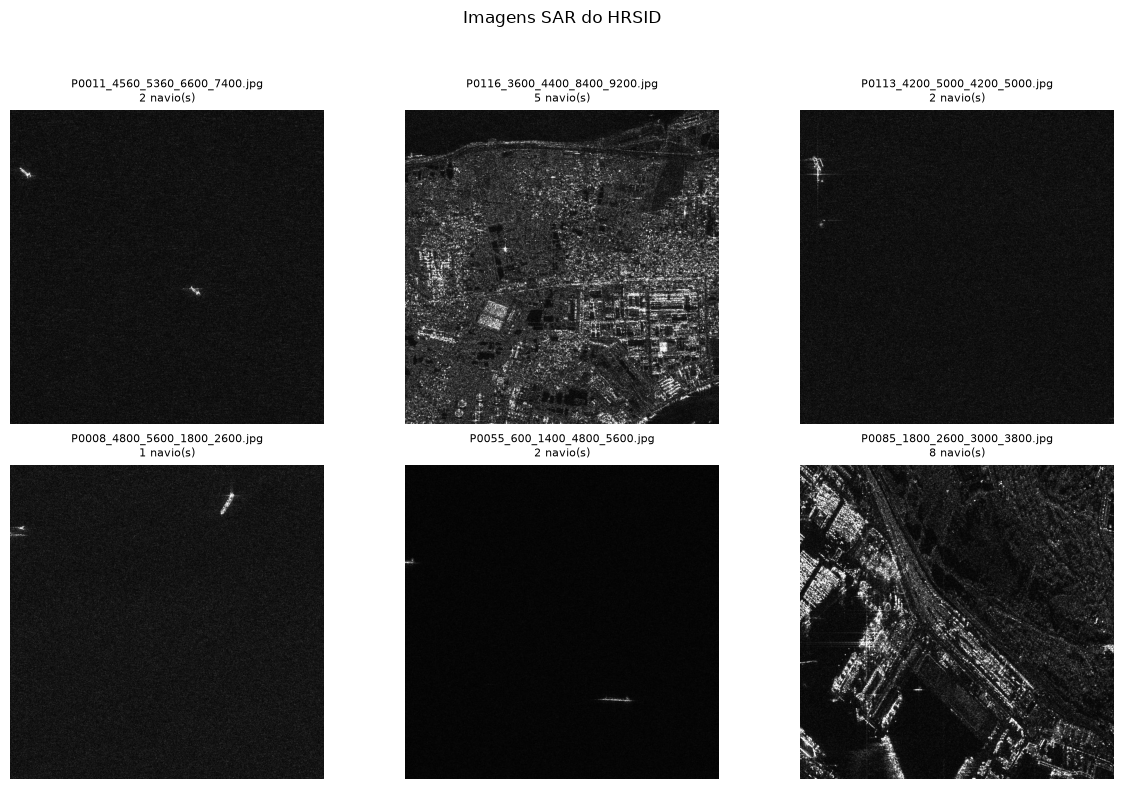

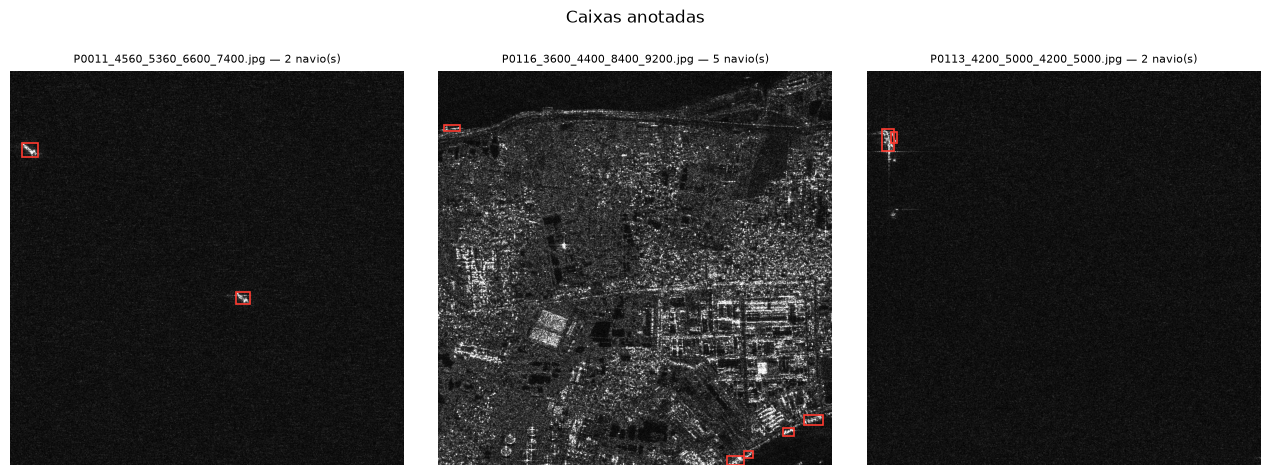

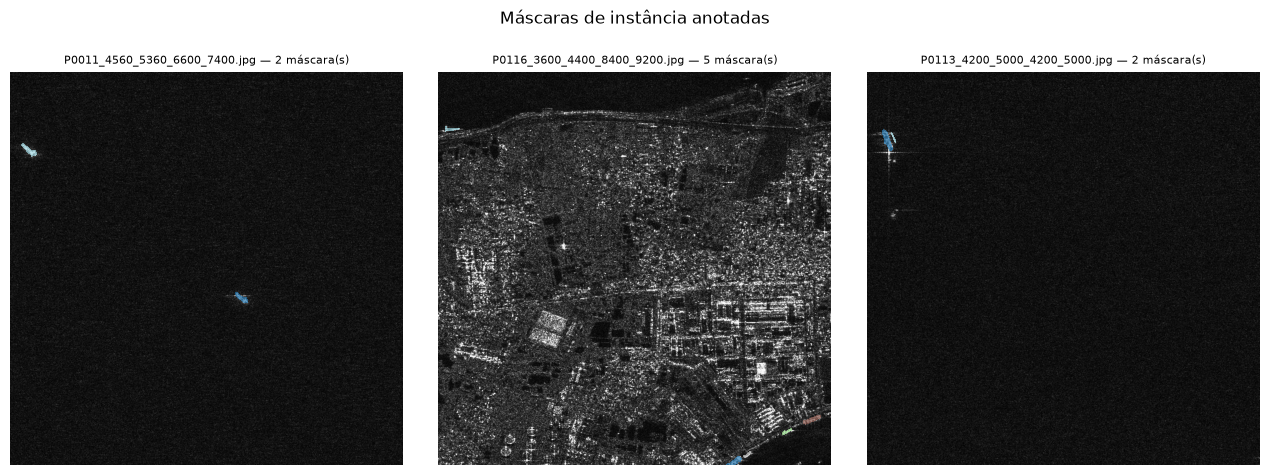

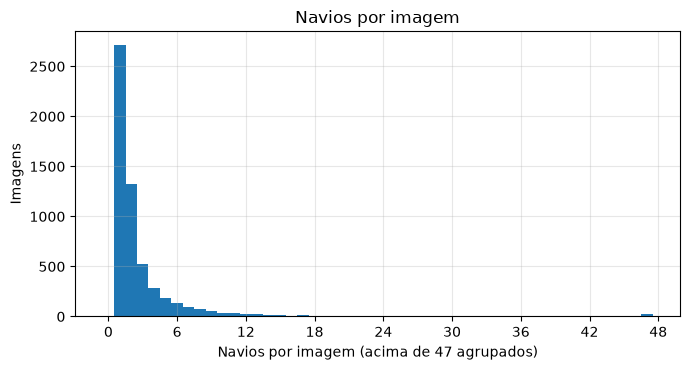

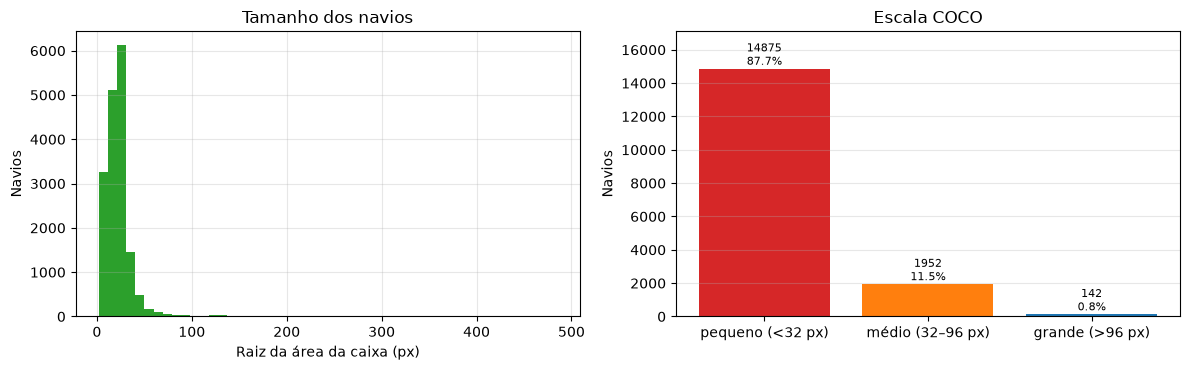

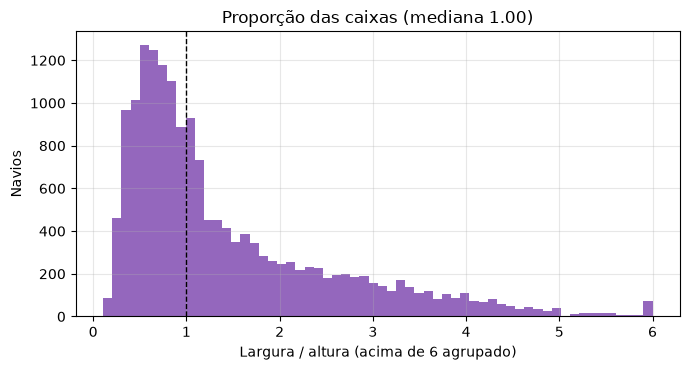

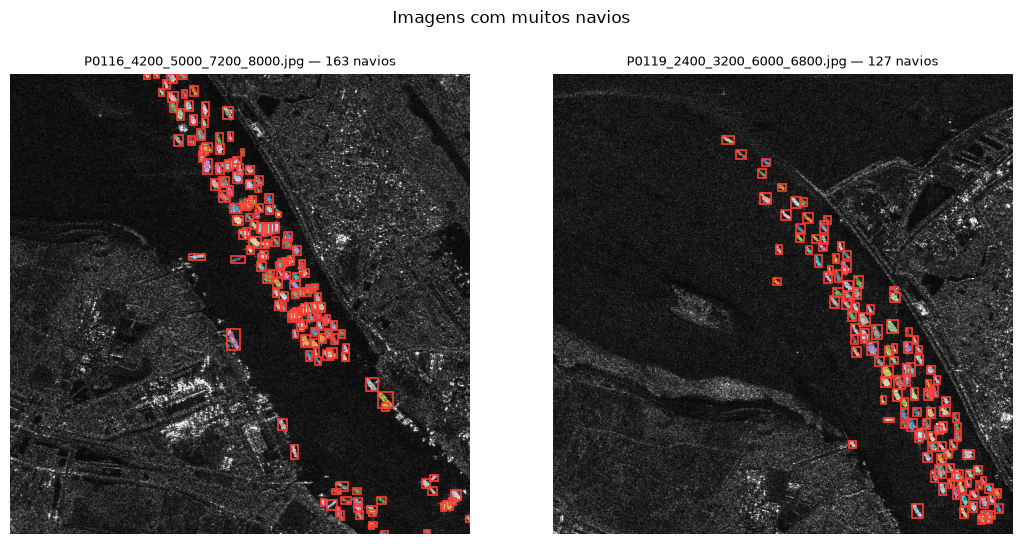

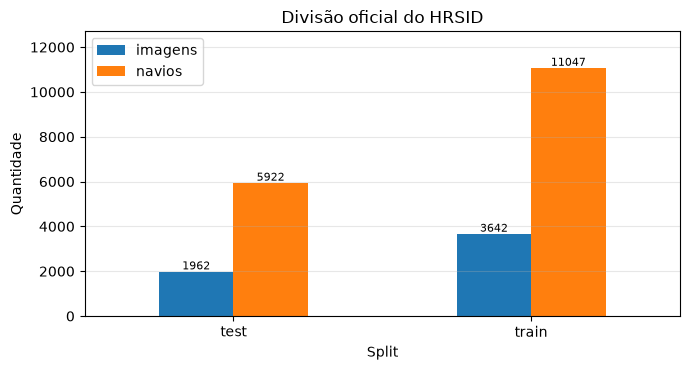

Imagens sem navio: 1 de 5604
Mediana de navios por imagem com alvo: 2.0


In [17]:
BOXES = annotations_frame(COCOS, EDA_SPLITS)
IMAGES = images_frame(COCOS, EDA_SPLITS)
EDA_SPLIT = EDA_SPLITS[0]
eda_frame = IMAGES[IMAGES.split == EDA_SPLIT]

plot_examples(COCOS[EDA_SPLIT], eda_frame, CONFIG['seed'])
plot_boxes(COCOS[EDA_SPLIT], eda_frame, CONFIG['seed'])
plot_masks(COCOS[EDA_SPLIT], eda_frame, CONFIG['seed'])
plot_ships_per_image(IMAGES)
plot_box_sizes(BOXES)
plot_aspect_ratio(BOXES)
plot_crowded(COCOS[EDA_SPLIT], eda_frame)
plot_split_statistics(IMAGES, BOXES)

print('Imagens sem navio:', int((IMAGES.navios == 0).sum()), 'de', len(IMAGES))
print('Mediana de navios por imagem com alvo:', IMAGES[IMAGES.navios > 0].navios.median())

## 6. Divisão dos dados

O HRSID já vem dividido em treino e teste; essa divisão é preservada. A validação sai **de dentro do treino oficial**, com semente fixa, e o teste oficial fica reservado para a avaliação final — nenhuma decisão de modelo usa o teste.

As imagens do HRSID são recortes de cenas SAR maiores, e o nome do arquivo guarda a cena de origem (`P0001_0_800_0_800.jpg` vem da cena `P0001`). Recortes vizinhos da mesma cena se parecem muito, então a validação leva **cenas inteiras**: sem isso, o mesmo navio poderia aparecer no treino e na validação e o resultado ficaria otimista. O notebook confere que nenhuma cena aparece dos dois lados.

In [18]:
def scene_id(file_name):
    """O HRSID recorta cenas grandes; o prefixo antes do primeiro '_' identifica a cena."""
    stem = Path(file_name).stem
    return stem.split('_')[0] if '_' in stem else stem


def scene_groups(coco, image_ids):
    groups = defaultdict(list)
    for image_id in image_ids:
        groups[scene_id(coco.imgs[image_id]['file_name'])].append(image_id)
    return groups


def split_validation(coco, image_ids, fraction, seed):
    """Separa cenas inteiras do treino oficial até cobrir a fração pedida de imagens."""
    groups = scene_groups(coco, image_ids)
    order = sorted(groups)
    if len(order) < 2:
        print('Apenas uma cena identificada: a validação será sorteada por imagem.')
        shuffled = sorted(image_ids)
        random.Random(seed).shuffle(shuffled)
        size = max(1, int(round(fraction * len(shuffled))))
        return sorted(shuffled[size:]), sorted(shuffled[:size])

    random.Random(seed).shuffle(order)
    chosen, count = set(), 0
    target = fraction * len(image_ids)
    for scene in order:
        if count >= target or len(chosen) == len(order) - 1:
            break
        chosen.add(scene)
        count += len(groups[scene])
    validation = sorted(image_id for scene in chosen for image_id in groups[scene])
    train = sorted(image_id for scene in order if scene not in chosen for image_id in groups[scene])
    return train, validation


def limit_ids(image_ids, limit, seed):
    """Reduz um split para ensaios rápidos, preservando a ordem original."""
    if not limit or len(image_ids) <= limit:
        return image_ids
    sample = random.Random(seed).sample(image_ids, limit)
    return sorted(sample)


if 'train' in COCOS and 'test' in COCOS:
    train_coco, test_coco = COCOS['train'], COCOS['test']
    train_ids, val_ids = split_validation(train_coco, sorted(train_coco.imgs), CONFIG['val_fraction'], CONFIG['seed'])
    test_ids = sorted(test_coco.imgs)
else:  # sem divisão oficial, separa cenas em treino/validação/teste
    name = next(iter(COCOS))
    train_coco = test_coco = COCOS[name]
    development, test_ids = split_validation(train_coco, sorted(train_coco.imgs), 0.3, CONFIG['seed'])
    train_ids, val_ids = split_validation(train_coco, development, CONFIG['val_fraction'] / 0.7, CONFIG['seed'])
    print(f'Divisão oficial ausente; treino, validação e teste derivados de {name} por cena.')

SPLITS = {
    'train': (train_coco, limit_ids(train_ids, CONFIG['limit_images'], CONFIG['seed'])),
    'validation': (train_coco, limit_ids(val_ids, CONFIG['limit_images'], CONFIG['seed'])),
    'test': (test_coco, limit_ids(test_ids, CONFIG['limit_images'], CONFIG['seed'])),
}

split_rows = [{'split': split, 'image_id': image_id, 'file_name': coco.imgs[image_id]['file_name'],
               'cena': scene_id(coco.imgs[image_id]['file_name'])}
              for split, (coco, ids) in SPLITS.items() for image_id in ids]
split_df = pd.DataFrame(split_rows)
split_df.to_csv(RESULTS / 'reports' / 'split.csv', index=False)

scenes = {split: set(frame.cena) for split, frame in split_df.groupby('split')}
print('Imagens por split:', split_df.split.value_counts().to_dict())
print('Cenas compartilhadas treino/validação:', sorted(scenes['train'] & scenes['validation']))
print('Cenas compartilhadas treino/teste:', len(scenes['train'] & scenes['test']))
display(split_df.groupby('split').cena.nunique().rename('cenas').to_frame())

Imagens por split: {'train': 3086, 'test': 1962, 'validation': 556}
Cenas compartilhadas treino/validação: []
Cenas compartilhadas treino/teste: 113


,cenas
split,
test,136
train,114
validation,23


## 7. Dataset PyTorch

O `HRSIDDataset` devolve `(image, target)` no formato que o Mask R-CNN do TorchVision espera:

- `boxes`: `float32` em XYXY absoluto — as caixas COCO vêm em XYWH e são convertidas aqui.
- `labels`: `int64`, sempre `1` (navio); o fundo é implícito.
- `masks`: `uint8` com uma máscara binária por instância, decodificada com `annToMask`, que trata tanto polígono quanto RLE.
- `image_id`, `area` e `iscrowd`, usados pela avaliação COCO.

A imagem SAR tem um canal; ela é replicada em três (`convert('RGB')`) porque o backbone pré-treinado espera três canais, e entra em `[0, 1]`. A normalização com médias e desvios do ImageNet acontece **dentro** do modelo (`GeneralizedRCNNTransform`), então não deve ser repetida aqui.

Anotações com caixa degenerada ou máscara vazia são descartadas, e caixa e máscara são removidas juntas — as duas listas sempre descrevem os mesmos objetos. Imagens sem navio devolvem tensores vazios com a forma correta, que o TorchVision aceita como exemplos negativos. A única aumentação é o espelhamento horizontal, aplicado à imagem, às caixas e às máscaras ao mesmo tempo.

In [19]:
class HRSIDDataset(Dataset):
    """Imagens SAR do HRSID com caixas XYXY e máscaras binárias por instância."""

    def __init__(self, coco, image_ids, images_dir, flip=0.0):
        self.coco = coco
        self.image_ids = list(image_ids)
        self.images_dir = images_dir
        self.flip = flip

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        info = self.coco.imgs[image_id]
        with Image.open(self.images_dir / info['file_name']) as image:
            tensor = pil_to_tensor(image.convert('RGB')).float() / 255.0
        height, width = tensor.shape[1], tensor.shape[2]

        boxes, masks, areas, crowds = [], [], [], []
        for annotation in self.coco.loadAnns(self.coco.getAnnIds(imgIds=image_id)):
            if not usable_annotation(annotation):  # caixa e máscara saem sempre juntas
                continue
            x, y, box_width, box_height = annotation['bbox']
            mask = self.coco.annToMask(annotation)
            if mask.sum() == 0:
                continue
            boxes.append([max(x, 0.0), max(y, 0.0), min(x + box_width, width), min(y + box_height, height)])
            masks.append(mask)
            areas.append(float(annotation.get('area', box_width * box_height)))
            crowds.append(int(annotation.get('iscrowd', 0)))

        target = {
            'boxes': torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            'labels': torch.full((len(boxes),), SHIP_LABEL, dtype=torch.int64),
            'masks': torch.as_tensor(np.stack(masks) if masks else np.zeros((0, height, width), dtype=np.uint8),
                                     dtype=torch.uint8),
            'image_id': torch.tensor(image_id, dtype=torch.int64),
            'area': torch.as_tensor(areas, dtype=torch.float32),
            'iscrowd': torch.as_tensor(crowds, dtype=torch.int64),
        }
        if self.flip and random.random() < self.flip:
            tensor, target = flip_horizontal(tensor, target)
        return tensor, target


def flip_horizontal(tensor, target):
    """Espelha imagem, caixas e máscaras na horizontal."""
    width = tensor.shape[2]
    boxes = target['boxes'].clone()
    boxes[:, [0, 2]] = width - target['boxes'][:, [2, 0]]
    return tensor.flip(-1), {**target, 'boxes': boxes, 'masks': target['masks'].flip(-1)}


def collate_fn(batch):
    """O detector recebe listas de imagens e de alvos, não tensores empilhados."""
    return tuple(zip(*batch))

## 8. DataLoaders

Um `DataLoader` por split, com `collate_fn` próprio porque as imagens podem ter tamanhos diferentes e cada alvo tem um número diferente de instâncias. Só o treino embaralha e aplica espelhamento. O gerador com semente fixa deixa a ordem reprodutível e também semeia os processos de leitura quando `num_workers > 0`.

In [20]:
def make_dataset(split, config):
    coco, image_ids = SPLITS[split]
    flip = config['horizontal_flip'] if split == 'train' else 0.0
    return HRSIDDataset(coco, image_ids, IMAGES_DIR, flip=flip)


def make_loader(split, config, shuffle=None):
    generator = torch.Generator().manual_seed(config['seed'])
    return DataLoader(datasets[split], batch_size=config['batch_size'],
                      shuffle=split == 'train' if shuffle is None else shuffle,
                      num_workers=config['num_workers'], collate_fn=collate_fn, generator=generator)


datasets = {split: make_dataset(split, CONFIG) for split in SPLITS}
loaders = {split: make_loader(split, CONFIG) for split in datasets}
print({split: len(dataset) for split, dataset in datasets.items()})

{'train': 3086, 'validation': 556, 'test': 1962}


## 9. Arquitetura do Mask R-CNN

O Mask R-CNN é um detector de dois estágios com uma cabeça extra de segmentação. Da imagem até as máscaras:

- **ResNet-50** — backbone convolucional de 50 camadas com blocos residuais. Extrai características cada vez mais abstratas: bordas e texturas nas camadas iniciais, partes e objetos inteiros nas finais.
- **FPN (Feature Pyramid Network)** — combina os mapas de várias profundidades num conjunto de escalas com a mesma riqueza semântica. É o que permite achar navios pequenos e grandes com o mesmo modelo, algo central no HRSID, onde a maioria dos alvos é pequena.
- **RPN (Region Proposal Network)** — percorre a pirâmide com âncoras de vários tamanhos e proporções e propõe as regiões que provavelmente contêm um objeto. É o primeiro estágio.
- **RoI Align** — recorta cada região proposta dos mapas de características num tamanho fixo usando interpolação bilinear, sem arredondar coordenadas. Esse alinhamento sub-pixel é o que torna a máscara precisa; era a limitação do RoI Pooling do Faster R-CNN.
- **Cabeça de detecção** — classifica cada região e refina a caixa.
- **Cabeça de máscara** — rede convolucional que prevê, para cada região, uma máscara binária por classe, com saída de 28×28 depois redimensionada para a caixa.

**Segmentação de instâncias** é mais do que segmentação semântica: não basta dizer quais pixels são navio, é preciso separar cada navio individualmente — dois navios encostados são duas instâncias, com máscaras distintas.

A versão **V2** (do artigo *Benchmarking Detection Transfer Learning with Vision Transformers*) moderniza o original: cabeças convolucionais mais profundas com normalização, RPN com duas convoluções e receita de treino mais forte. Ela entrega mAP maior que a V1 com o mesmo backbone.

## 10. Pesos pré-treinados do COCO

`MaskRCNN_ResNet50_FPN_V2_Weights.COCO_V1` traz o modelo treinado no COCO: cerca de 118 mil fotografias naturais e 80 categorias de objetos do dia a dia, com máscaras anotadas. Nenhuma dessas categorias é um navio visto por radar, e as imagens SAR não se parecem com fotografias: são em tons de cinza, vistas de cima, com ruído *speckle* e alvos brilhantes sobre o mar escuro.

Mesmo assim a transferência compensa: as camadas iniciais aprendem bordas, cantos e texturas que existem em qualquer imagem, e a FPN, a RPN e o RoI Align já sabem propor e recortar objetos. O que precisa mudar é a parte específica da tarefa — e cada estratégia do `CONFIG` libera uma parte diferente dela.

In [21]:
WEIGHTS = MaskRCNN_ResNet50_FPN_V2_Weights.COCO_V1
print('Pesos:', WEIGHTS)
print('Categorias no COCO:', len(WEIGHTS.meta['categories']))
print('Métricas originais:', WEIGHTS.meta['_metrics'])
print('Pré-processamento:', WEIGHTS.transforms())

Pesos: MaskRCNN_ResNet50_FPN_V2_Weights.COCO_V1
Categorias no COCO: 91
Métricas originais: {'COCO-val2017': {'box_map': 47.4, 'mask_map': 41.8}}
Pré-processamento: ObjectDetection()


## 11. Adaptação do modelo

O modelo completo é carregado com os pesos do COCO e só as duas cabeças finais são trocadas:

- `FastRCNNPredictor` — classificação e regressão de caixa, com duas saídas de classe: `0` fundo e `1` navio.
- `MaskRCNNPredictor` — máscara por classe, também com duas saídas.

As cabeças novas nascem com pesos aleatórios, porque o número de saídas mudou; backbone, FPN, RPN, RoI Align e as cabeças intermediárias (`box_head`, `mask_head`) continuam com os pesos do COCO. Nada do Mask R-CNN é reimplementado à mão: tudo vem das classes oficiais do TorchVision.

`trainable_backbone_layers` é o parâmetro oficial do construtor para congelar blocos do ResNet-50, contados do fim para o começo: `0` congela o backbone inteiro, `2` libera `layer3` e `layer4`, `5` libera tudo.

In [22]:
BACKBONE_BLOCKS = ('conv1', 'bn1', 'layer1', 'layer2', 'layer3', 'layer4')
STRATEGIES = {'frozen_backbone': 0, 'partial_finetune': None, 'full_finetune': 5}


def trainable_layers(config):
    """Quantos blocos finais do ResNet-50 recebem gradiente nesta estratégia."""
    if config['experiment'] not in STRATEGIES:
        raise ValueError(f'Experimento desconhecido: {config["experiment"]}. Use {sorted(STRATEGIES)}.')
    fixed = STRATEGIES[config['experiment']]
    return int(config['trainable_layers']) if fixed is None else fixed


def make_model(config):
    """Mask R-CNN V2 com pesos COCO e cabeças trocadas por versões de duas classes."""
    model = maskrcnn_resnet50_fpn_v2(weights=WEIGHTS, trainable_backbone_layers=trainable_layers(config))
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)
    in_channels = model.roi_heads.mask_predictor.conv5_mask.in_channels
    model.roi_heads.mask_predictor = MaskRCNNPredictor(in_channels, MASK_HIDDEN_LAYER, NUM_CLASSES)
    if config['experiment'] == 'frozen_backbone':
        model.backbone.fpn.requires_grad_(False)  # o corpo já vem congelado por trainable_backbone_layers=0
    return model

## 12. Configuração da transferência

As estratégias disponíveis em `CONFIG['experiment']` usam os mesmos pesos iniciais e diferem apenas no que recebe gradiente:

| `experiment` | Treinado | Congelado |
| --- | --- | --- |
| `frozen_backbone` | RPN, cabeças de detecção e de máscara | ResNet-50 e FPN |
| `partial_finetune` | blocos finais do ResNet-50 (`trainable_layers`), FPN, RPN e as cabeças | blocos iniciais do ResNet-50 |
| `full_finetune` | tudo | nada |

O `maskrcnn_resnet50_fpn_v2` usa `BatchNorm2d` comum, e não `FrozenBatchNorm2d`: zerar o gradiente não basta, porque as médias e variâncias continuariam sendo atualizadas a cada batch. Por isso os blocos congelados ficam em `eval()` durante o treino, o que mantém as estatísticas do COCO.

A tabela abaixo mostra exatamente quantos parâmetros cada parte tem e quais estão treinando. O notebook executa um experimento por vez: `CONFIG['experiment']` escolhe qual.

In [23]:
def frozen_modules(model, config):
    """Submódulos sem gradiente: ficam em eval para não atualizar as estatísticas de BatchNorm."""
    trainable = ['layer4', 'layer3', 'layer2', 'layer1', 'conv1'][:trainable_layers(config)]
    if trainable_layers(config) == 5:
        trainable.append('bn1')
    modules = [getattr(model.backbone.body, name) for name in BACKBONE_BLOCKS if name not in trainable]
    if config['experiment'] == 'frozen_backbone':
        modules.append(model.backbone.fpn)
    return modules


def set_train_mode(model, config):
    """Coloca o modelo em treino mantendo os blocos congelados em eval."""
    model.train()
    for module in frozen_modules(model, config):
        module.eval()


def parameter_summary(model):
    """Parâmetros treináveis e congelados por parte do modelo."""
    parts = {
        'backbone.body (ResNet-50)': model.backbone.body,
        'backbone.fpn': model.backbone.fpn,
        'rpn': model.rpn,
        'roi_heads.box_head': model.roi_heads.box_head,
        'roi_heads.box_predictor': model.roi_heads.box_predictor,
        'roi_heads.mask_head': model.roi_heads.mask_head,
        'roi_heads.mask_predictor': model.roi_heads.mask_predictor,
    }
    rows = [{'parte': name,
             'treináveis': sum(p.numel() for p in part.parameters() if p.requires_grad),
             'congelados': sum(p.numel() for p in part.parameters() if not p.requires_grad)}
            for name, part in parts.items()]
    frame = pd.DataFrame(rows).set_index('parte')
    frame.loc['total'] = frame.sum()
    return frame


model = make_model(CONFIG)
print(f'Experimento: {CONFIG["experiment"]} | blocos do ResNet-50 liberados: {trainable_layers(CONFIG)}')
print('Blocos em eval durante o treino:', [type(module).__name__ for module in frozen_modules(model, CONFIG)])
display(parameter_summary(model))

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /home/miguelherdian/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:12<00:00, 15.4MB/s] 


Experimento: frozen_backbone | blocos do ResNet-50 liberados: 0
Blocos em eval durante o treino: ['Conv2d', 'BatchNorm2d', 'Sequential', 'Sequential', 'Sequential', 'Sequential', 'FeaturePyramidNetwork']


,treináveis,congelados
parte,,
backbone.body (ResNet-50),0,23508032
backbone.fpn,0,3346432
rpn,1184015,0
roi_heads.box_head,15207424,0
roi_heads.box_predictor,10250,0
roi_heads.mask_head,2361344,0
roi_heads.mask_predictor,262914,0
total,19025947,26854464


## 13. Treinamento

Cada rodada cria uma pasta própria em `runs/results/hrsid_mask_rcnn_v2/<experimento>/<data_hora>/`, com `config.json`, histórico, figuras, checkpoint e métricas — rodadas antigas não são apagadas.

O otimizador é o AdamW: a taxa de 1e-4 do `CONFIG` é a escala típica desse otimizador em fine-tuning de detectores; com SGD, a mesma taxa seria baixa demais. O agendamento é um cosseno que leva a taxa a zero ao longo das épocas. Em CUDA, `amp=True` liga a precisão mista, que reduz memória e tempo sem mudar imagens nem arquitetura.

Em modo de treino, o detector do TorchVision recebe `(images, targets)` e devolve **um dicionário de perdas**, não predições: classificação, regressão de caixa, máscara e as duas perdas da RPN. Em modo de avaliação, recebe só as imagens e devolve predições. São APIs diferentes, e por isso não existe "perda de validação" aqui: a validação é medida por mAP, não por perda.

In [24]:
def create_run(config):
    """Cria a pasta exclusiva da rodada dentro do experimento escolhido."""
    base = RESULTS / config['experiment']
    base.mkdir(parents=True, exist_ok=True)
    while True:
        run_dir = base / f'{datetime.now():%Y%m%d_%H%M%S_%f}'
        try:
            run_dir.mkdir()
            break
        except FileExistsError:
            continue
    for name in ('figures', 'checkpoints', 'predictions', 'reports'):
        (run_dir / name).mkdir()
    (run_dir / 'config.json').write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding='utf-8')
    split_df.to_csv(run_dir / 'reports' / 'split.csv', index=False)
    return run_dir


def train_one_epoch(model, loader, optimizer, scaler, device, config):
    """Uma passagem de treino; devolve a média de cada componente da perda."""
    set_train_mode(model, config)
    totals = Counter()
    for images, targets in tqdm(loader, desc='Treino', leave=False):
        images = [image.to(device) for image in images]
        targets = [{key: value.to(device) for key, value in target.items()} for target in targets]
        with torch.autocast(device.type, enabled=scaler.is_enabled()):
            losses = model(images, targets)
            loss = sum(losses.values())
        if not torch.isfinite(loss):
            raise RuntimeError('Perda não finita')
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        totals.update({name: float(value) for name, value in losses.items()})
        totals['train_loss'] += float(loss)
    return {name: value / len(loader) for name, value in totals.items()}

## 14. Validação e escolha do checkpoint

A validação roda a cada época sobre as cenas separadas na seção 6. O checkpoint guardado é o da melhor **mAP@0.50:0.95 de máscara**, porque a segmentação é a tarefa final deste estudo; o treino para depois de `patience` épocas sem ganho. Além dos pesos, o checkpoint guarda otimizador, agendador, escala do AMP, época e o `CONFIG` da rodada, o que permite retomar ou reavaliar depois.

In [25]:
MONITOR = 'mask_map_50_95'

CURVES = [
    ('box_map_50', 'Box mAP@0.50', (0, 1.02)),
    ('box_map_50_95', 'Box mAP@0.50:0.95', (0, 1.02)),
    ('mask_map_50', 'Mask mAP@0.50', (0, 1.02)),
    ('mask_map_50_95', 'Mask mAP@0.50:0.95', (0, 1.02)),
    ('box_f1', 'F1 das caixas', (0, 1.02)),
    ('mask_f1', 'F1 das máscaras', (0, 1.02)),
    ('train_loss', 'Perda de treino', None),
]


def mask_iou(predicted, target):
    """IoU entre máscaras binárias, no formato (predições, alvos)."""
    if not len(predicted) or not len(target):
        return torch.zeros(len(predicted), len(target))
    left = predicted.flatten(1).float()
    right = target.flatten(1).float()
    intersection = left @ right.t()
    union = left.sum(1)[:, None] + right.sum(1)[None, :] - intersection
    return intersection / union.clamp(min=1.0)


def count_matches(scores, ious, threshold):
    """Casa cada predição com o alvo livre de maior IoU, da maior para a menor confiança."""
    taken, matched = set(), 0
    for index in torch.argsort(scores, descending=True).tolist():
        candidates = [j for j in range(ious.shape[1]) if j not in taken and ious[index, j] >= threshold]
        if candidates:
            taken.add(max(candidates, key=lambda j: float(ious[index, j])))
            matched += 1
    return matched


def rates(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, recall, f1


def evaluate(model, loader, device, config):
    """Avalia caixas e máscaras: mAP no protocolo COCO e precisão/recall nos limiares do CONFIG."""
    use_amp = config['amp'] and device.type == 'cuda'
    metric = MeanAveragePrecision(box_format='xyxy', iou_type=('bbox', 'segm'), backend='pycocotools')
    counts = {'box': [0, 0, 0], 'mask': [0, 0, 0]}
    model.eval()
    with torch.no_grad():
        for images, targets in tqdm(loader, desc='Avaliação', leave=False):
            with torch.autocast(device.type, enabled=use_amp):
                outputs = model([image.to(device) for image in images])
            predictions = []
            for output in outputs:
                # Converte para FP32: as métricas não devem depender da precisão do forward.
                scores = output['scores'].float().cpu()
                predictions.append({
                    'boxes': output['boxes'].float().cpu(),
                    'scores': scores,
                    'labels': output['labels'].cpu(),
                    'masks': (output['masks'].float().cpu().squeeze(1) >= config['mask_threshold']),
                })
            references = [{'boxes': target['boxes'], 'labels': target['labels'],
                           'masks': target['masks'].bool(), 'iscrowd': target['iscrowd']} for target in targets]
            metric.update(predictions, references)

            for prediction, reference in zip(predictions, references):
                keep = prediction['scores'] >= config['confidence_threshold']
                scores = prediction['scores'][keep]
                pairs = {'box': box_iou(prediction['boxes'][keep], reference['boxes']),
                         'mask': mask_iou(prediction['masks'][keep], reference['masks'])}
                for kind, ious in pairs.items():
                    matched = count_matches(scores, ious, config['iou_threshold'])
                    counts[kind][0] += matched
                    counts[kind][1] += int(keep.sum()) - matched
                    counts[kind][2] += len(reference['boxes']) - matched

    coco = metric.compute()
    metrics = {
        'box_map_50': float(coco['bbox_map_50']), 'box_map_50_95': float(coco['bbox_map']),
        'mask_map_50': float(coco['segm_map_50']), 'mask_map_50_95': float(coco['segm_map']),
    }
    for kind, (tp, fp, fn) in counts.items():
        precision, recall, f1 = rates(tp, fp, fn)
        metrics.update({f'{kind}_precision': precision, f'{kind}_recall': recall, f'{kind}_f1': f1,
                        f'{kind}_tp': tp, f'{kind}_fp': fp, f'{kind}_fn': fn})
    return metrics


def draw_curve(ax, frame, key, title, limits):
    ax.plot(frame.epoch, frame[key], marker='o', linewidth=1.8)
    ax.set(xlabel='Época', ylabel=title, title=title)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    if limits is not None:
        ax.set_ylim(*limits)
    ax.grid(alpha=0.3)


def plot_history(history, run_dir):
    """Salva uma figura por métrica e um painel com todas elas."""
    frame = pd.DataFrame(history)
    for key, title, limits in CURVES:
        fig, ax = plt.subplots(figsize=(5, 3.5))
        draw_curve(ax, frame, key, title, limits)
        fig.tight_layout()
        fig.savefig(run_dir / 'figures' / f'curve_{key}.png', dpi=150)
        plt.close(fig)

    fig, axes = plt.subplots(3, 3, figsize=(15, 11))
    for ax, curve in zip(axes.ravel(), CURVES):
        draw_curve(ax, frame, *curve)
    for ax in axes.ravel()[len(CURVES):]:
        ax.axis('off')
    fig.suptitle('Validação por época')
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    fig.savefig(run_dir / 'figures' / 'training_curves.png', dpi=150)
    display(fig)
    plt.close(fig)


def train_experiment(config, run_dir):
    """Treina a estratégia escolhida e guarda o melhor checkpoint pela validação."""
    set_seed(config['seed'])
    model = make_model(config).to(DEVICE)
    parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
    optimizer = torch.optim.AdamW(parameters, lr=config['learning_rate'], weight_decay=config['weight_decay'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config['epochs'])
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=config['amp'] and DEVICE.type == 'cuda')
    parameter_summary(model).to_csv(run_dir / 'reports' / 'parameters.csv')

    train_loader = make_loader('train', config)
    checkpoint = run_dir / 'checkpoints' / 'best.pt'
    history, best, stale = [], -1.0, 0

    for epoch in range(1, config['epochs'] + 1):
        losses = train_one_epoch(model, train_loader, optimizer, scaler, DEVICE, config)
        metrics = evaluate(model, loaders['validation'], DEVICE, config)
        scheduler.step()

        history.append({'epoch': epoch, 'lr': optimizer.param_groups[0]['lr'], **losses, **metrics})
        pd.DataFrame(history).to_csv(run_dir / 'reports' / 'history.csv', index=False)
        plot_history(history, run_dir)
        print(f'Época {epoch}: perda={losses["train_loss"]:.4f} (máscara={losses["loss_mask"]:.4f}) | '
              f'box mAP={metrics["box_map_50_95"]:.3f} | mask mAP={metrics["mask_map_50_95"]:.3f} | '
              f'mask F1={metrics["mask_f1"]:.3f}')

        if metrics[MONITOR] > best:
            best, stale = metrics[MONITOR], 0
            torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                        'scheduler': scheduler.state_dict(), 'scaler': scaler.state_dict(), 'epoch': epoch,
                        'config': dict(config), 'best': best, 'metrics': metrics}, checkpoint)
            (run_dir / 'reports' / 'metrics_validation.json').write_text(
                json.dumps({'epoch': epoch, **metrics}, indent=2), encoding='utf-8')
        else:
            stale += 1
            if stale >= config['patience']:
                print('Early stopping')
                break
    print(f'Melhor {MONITOR}: {best:.4f} | checkpoint: {checkpoint}')
    return checkpoint


def load_checkpoint(path, device):
    """Carrega um checkpoint da rodada. Use apenas arquivos de origem confiável."""
    path = Path(path)
    path = path if path.is_absolute() else ROOT / path
    saved = torch.load(path, map_location='cpu', weights_only=False)
    model = make_model(saved['config']).to(device)
    model.load_state_dict(saved['model'])
    return model, saved

## 15. Avaliação da detecção

Detecção e segmentação são medidas separadamente, com o mesmo conjunto de predições. Para as caixas, o protocolo COCO (via `pycocotools`) dá **mAP@0.50** e **mAP@0.50:0.95**, que varrem todas as faixas de confiança e não dependem de `confidence_threshold`.

Precisão, recall e F1 completam a leitura num ponto de operação concreto: só entram predições com confiança acima de `CONFIG['confidence_threshold']` (0,5), e um acerto exige IoU de caixa acima de `CONFIG['iou_threshold']` (0,5), com cada alvo casado no máximo uma vez. Esses dois limiares precisam ser informados junto do número — sozinho, um F1 não quer dizer nada.

## 16. Avaliação da segmentação de instâncias

As mesmas métricas são recalculadas sobre as máscaras: a IoU é computada entre máscaras binárias, depois de limiarizar a saída do modelo em `CONFIG['mask_threshold']` (0,5), e não entre caixas. Uma caixa certa com máscara ruim derruba a mAP de máscara sem afetar a de caixa, e é essa diferença que mostra o custo real da segmentação.

Métricas nunca são inventadas: as tabelas só aparecem depois de uma avaliação executada. A validação orienta as decisões durante o estudo; o teste oficial é avaliado uma única vez, no fim.

In [26]:
METRIC_ROWS = [('mAP@0.50', '{}_map_50'), ('mAP@0.50:0.95', '{}_map_50_95'),
               ('precisão', '{}_precision'), ('recall', '{}_recall'), ('F1', '{}_f1'),
               ('TP', '{}_tp'), ('FP', '{}_fp'), ('FN', '{}_fn')]


def metrics_table(metrics):
    """Métricas de detecção e de segmentação lado a lado."""
    return pd.DataFrame(
        {'detecção (caixas)': [metrics[key.format('box')] for _, key in METRIC_ROWS],
         'segmentação (máscaras)': [metrics[key.format('mask')] for _, key in METRIC_ROWS]},
        index=[label for label, _ in METRIC_ROWS]).round(4)


def save_metrics(metrics, run_dir, tag):
    """Guarda as métricas da avaliação e mostra as duas tabelas."""
    (run_dir / 'reports' / f'metrics_{tag}.json').write_text(
        json.dumps(metrics, indent=2), encoding='utf-8')
    table = metrics_table(metrics)
    table.to_csv(run_dir / 'reports' / f'metrics_{tag}.csv')
    print(f'Avaliação — {tag} (confiança {CONFIG["confidence_threshold"]}, IoU {CONFIG["iou_threshold"]}, '
          f'máscara {CONFIG["mask_threshold"]})')
    display(table)
    return table

Rodada: /home/miguelherdian/Faculdade_Visao_Computacional/vision-transfer-learning/runs/results/hrsid_mask_rcnn_v2/frozen_backbone/20261108_130031_816248


Treino:   0%|          | 0/1543 [00:00<?, ?it/s]/tmp/ipykernel_222892/1962392256.py:35: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  totals.update({name: float(value) for name, value in losses.items()})


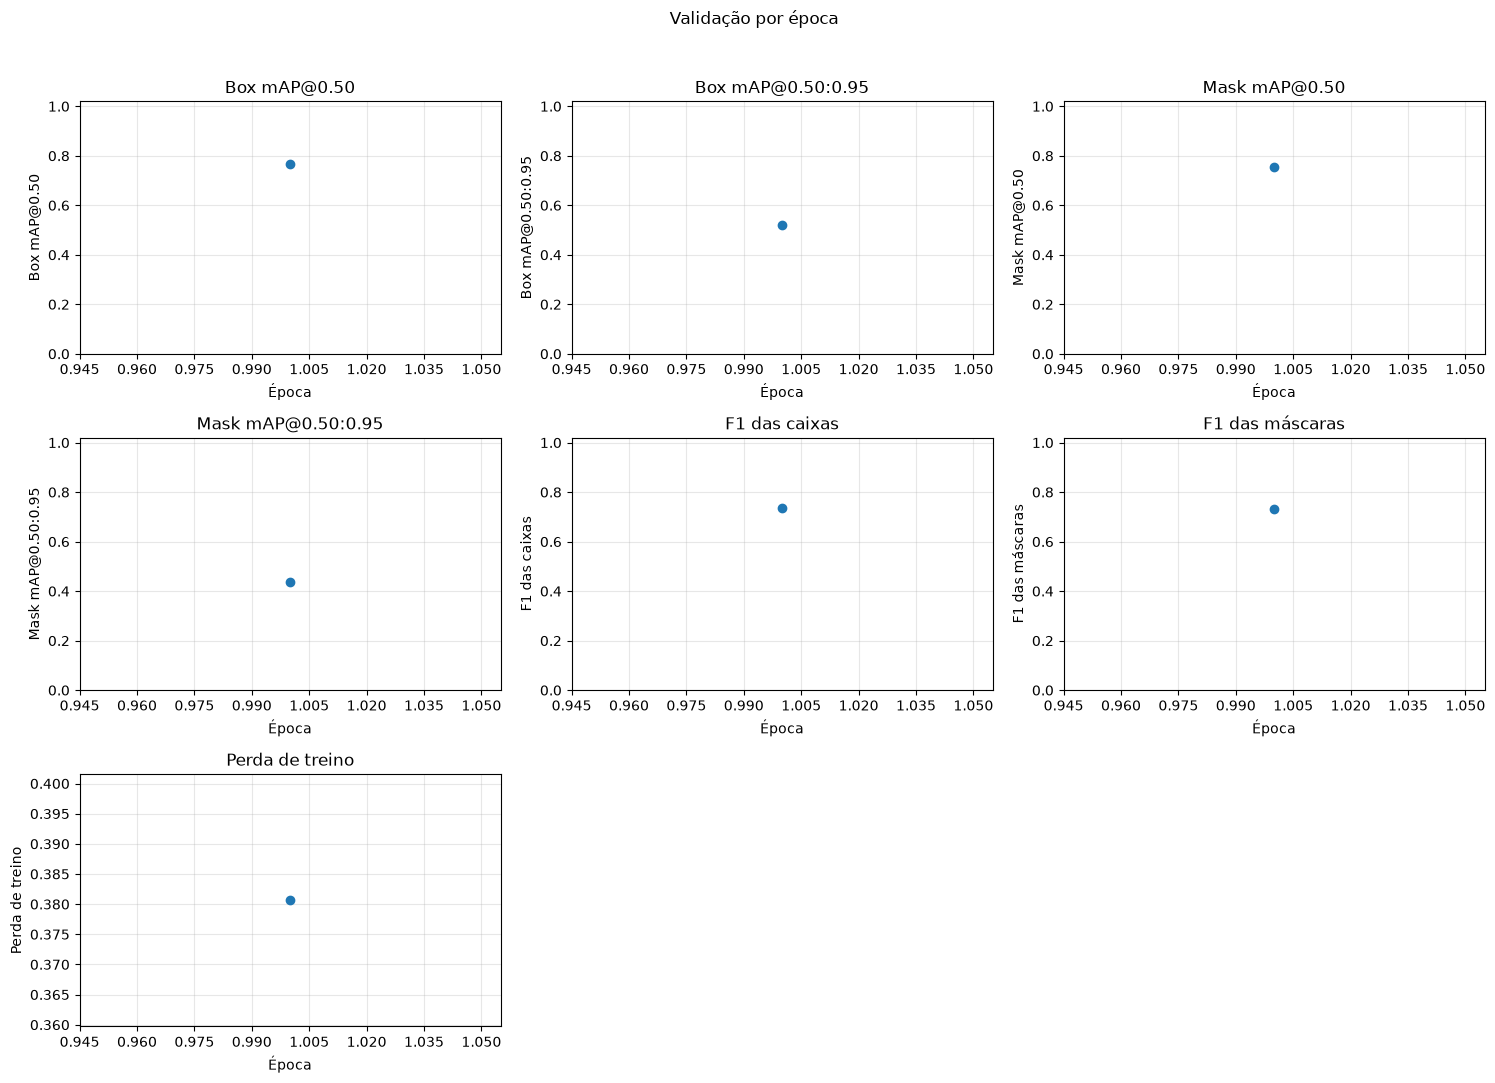

Época 1: perda=0.3806 (máscara=0.1953) | box mAP=0.521 | mask mAP=0.438 | mask F1=0.732


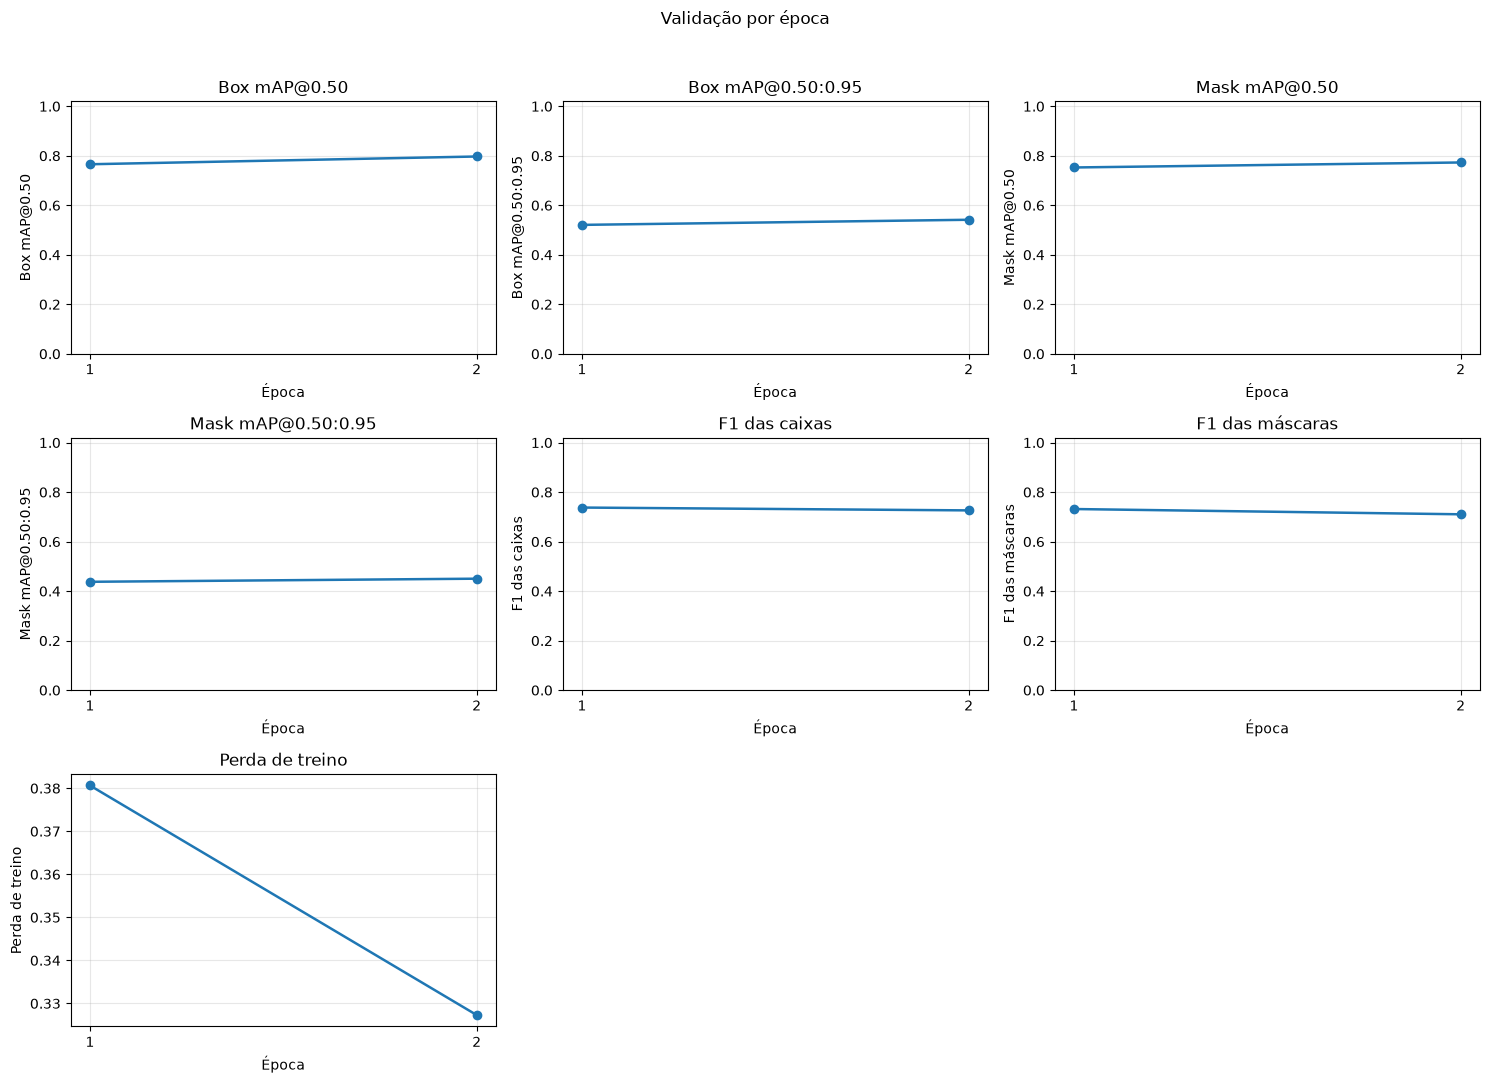

Época 2: perda=0.3273 (máscara=0.1756) | box mAP=0.542 | mask mAP=0.450 | mask F1=0.710


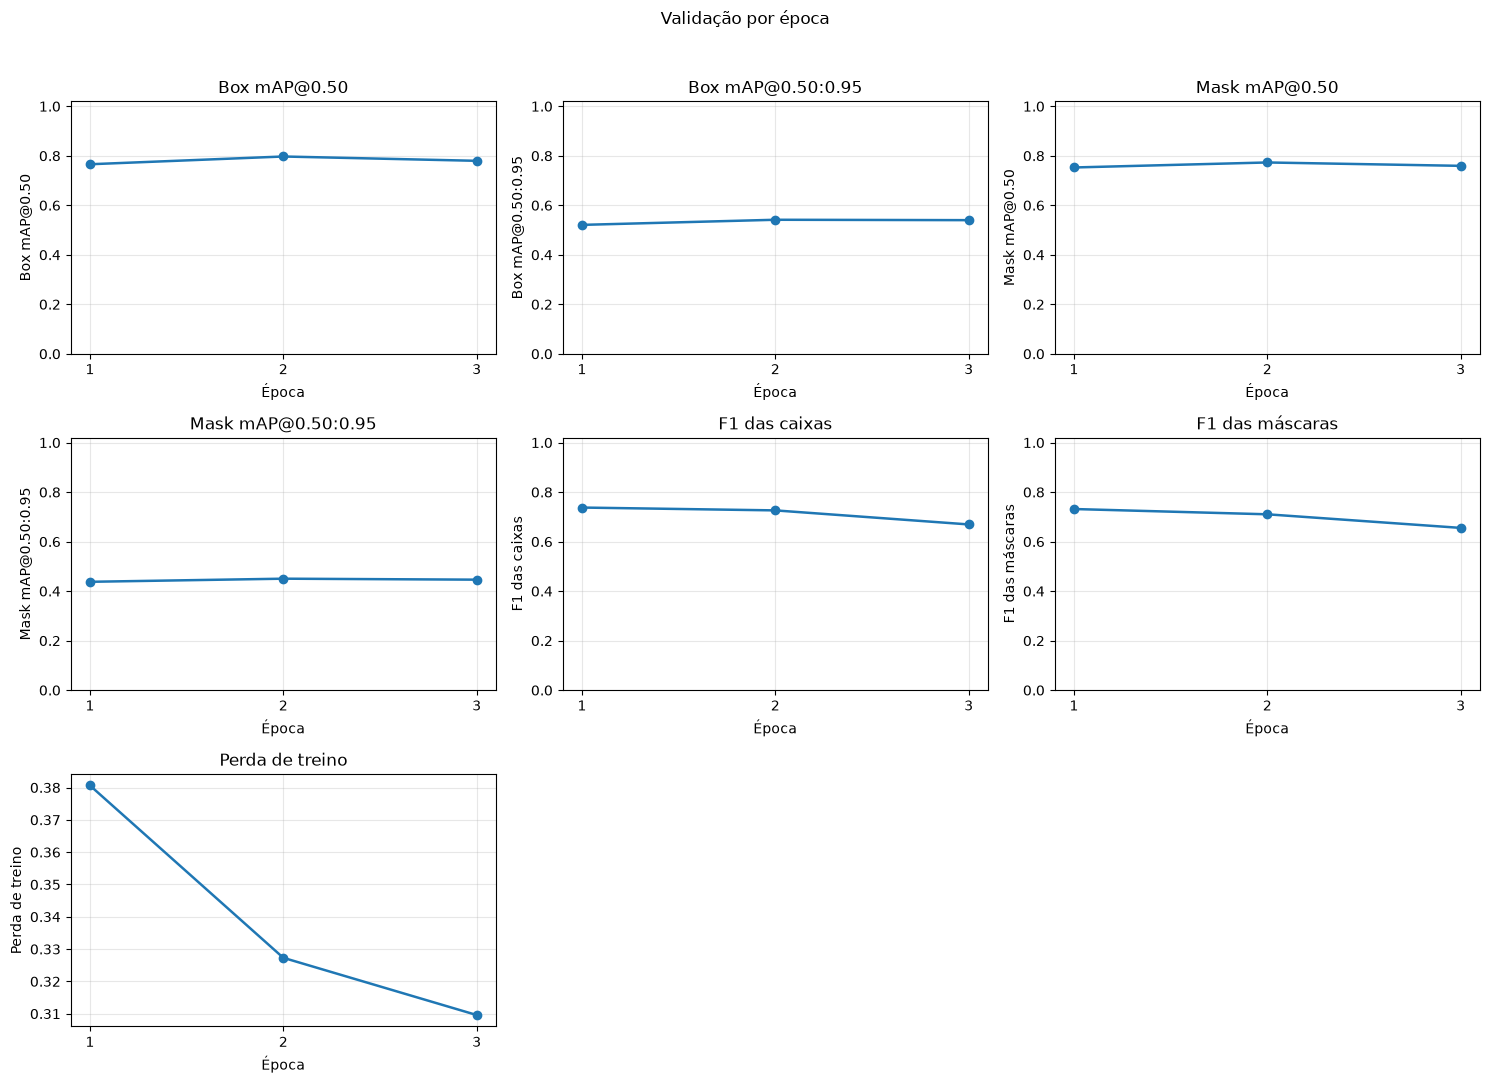

Época 3: perda=0.3096 (máscara=0.1715) | box mAP=0.540 | mask mAP=0.446 | mask F1=0.656


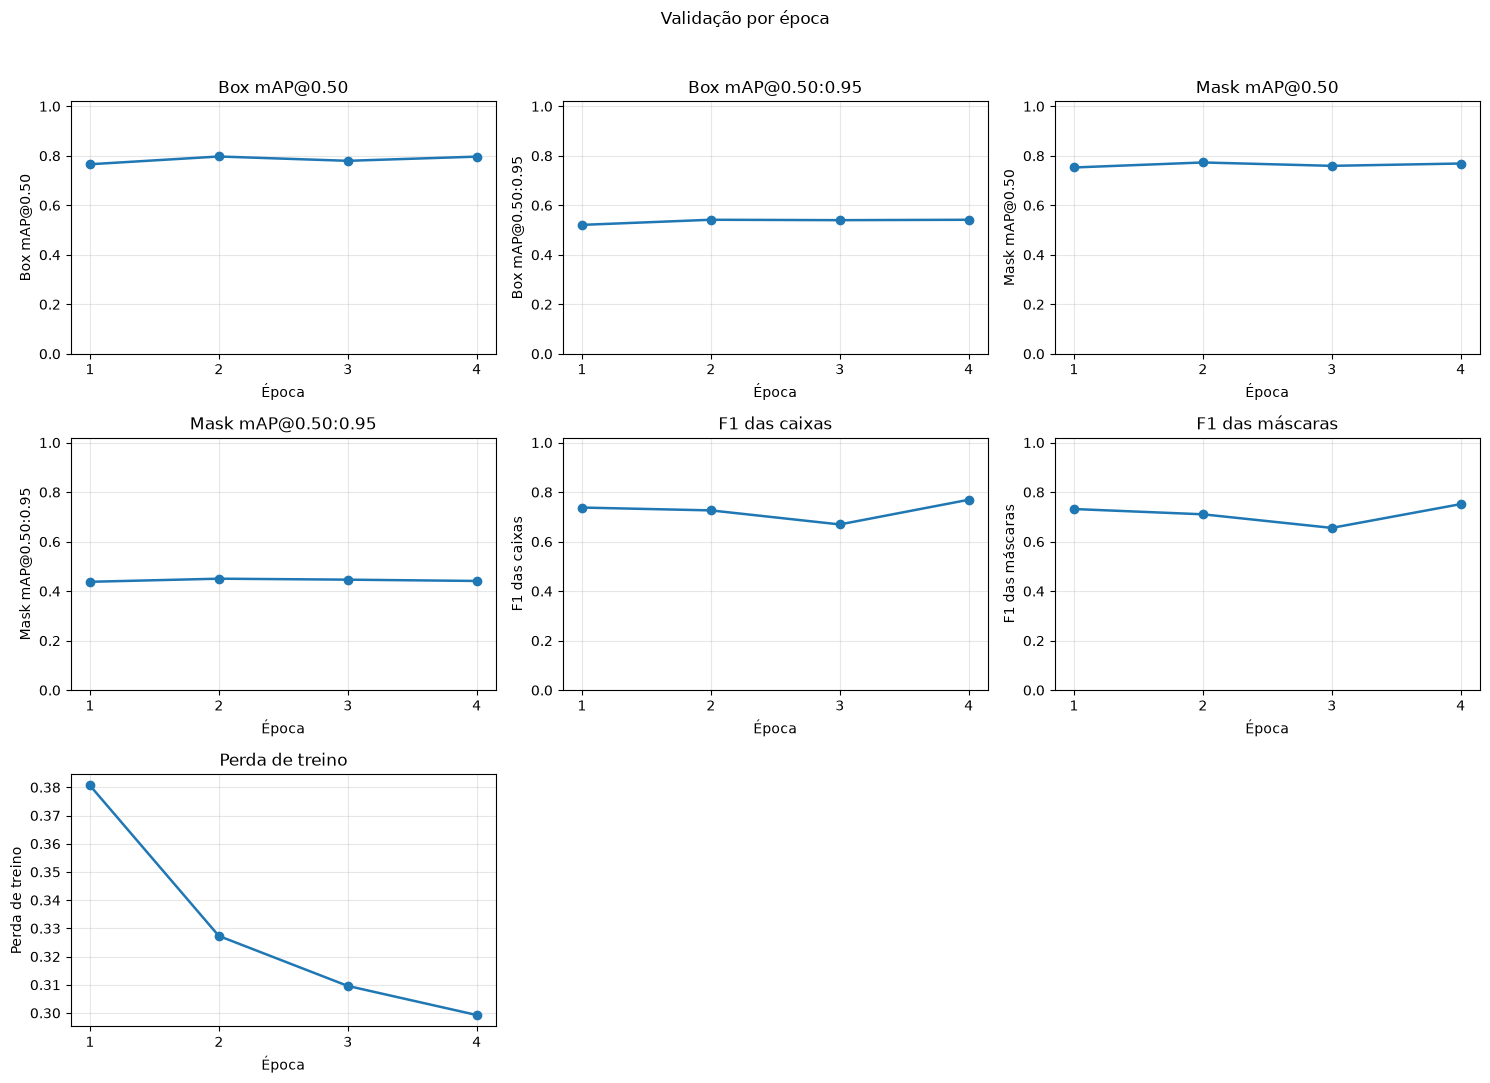

Época 4: perda=0.2993 (máscara=0.1664) | box mAP=0.542 | mask mAP=0.441 | mask F1=0.752


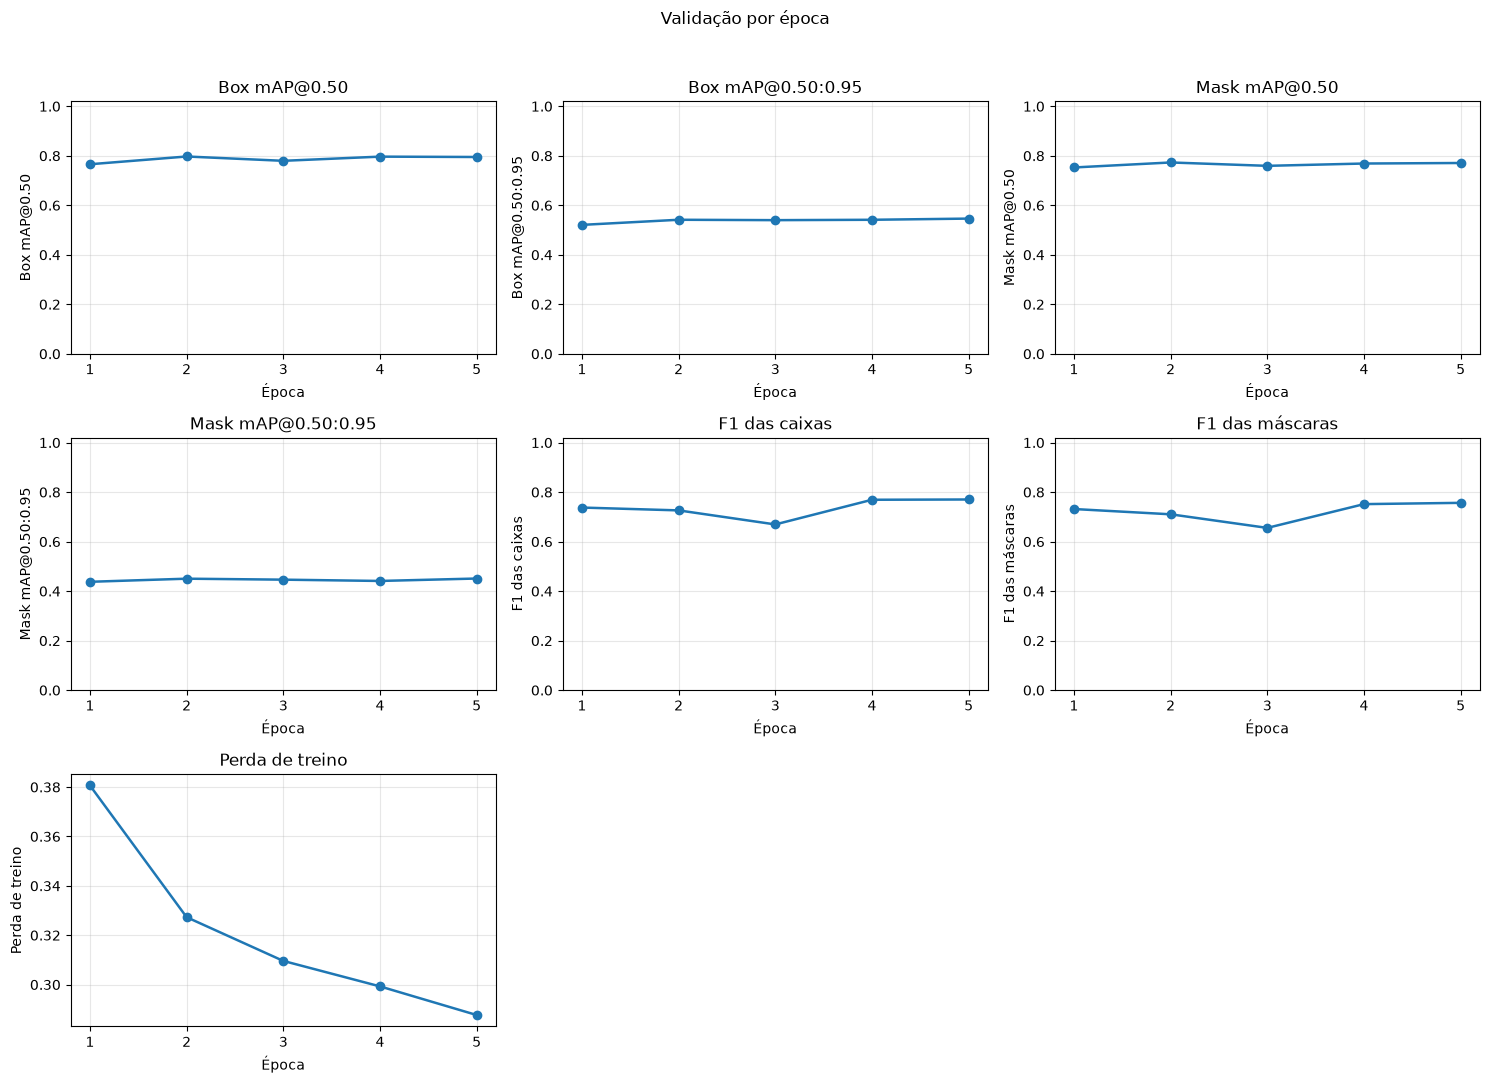

Época 5: perda=0.2877 (máscara=0.1621) | box mAP=0.546 | mask mAP=0.451 | mask F1=0.757


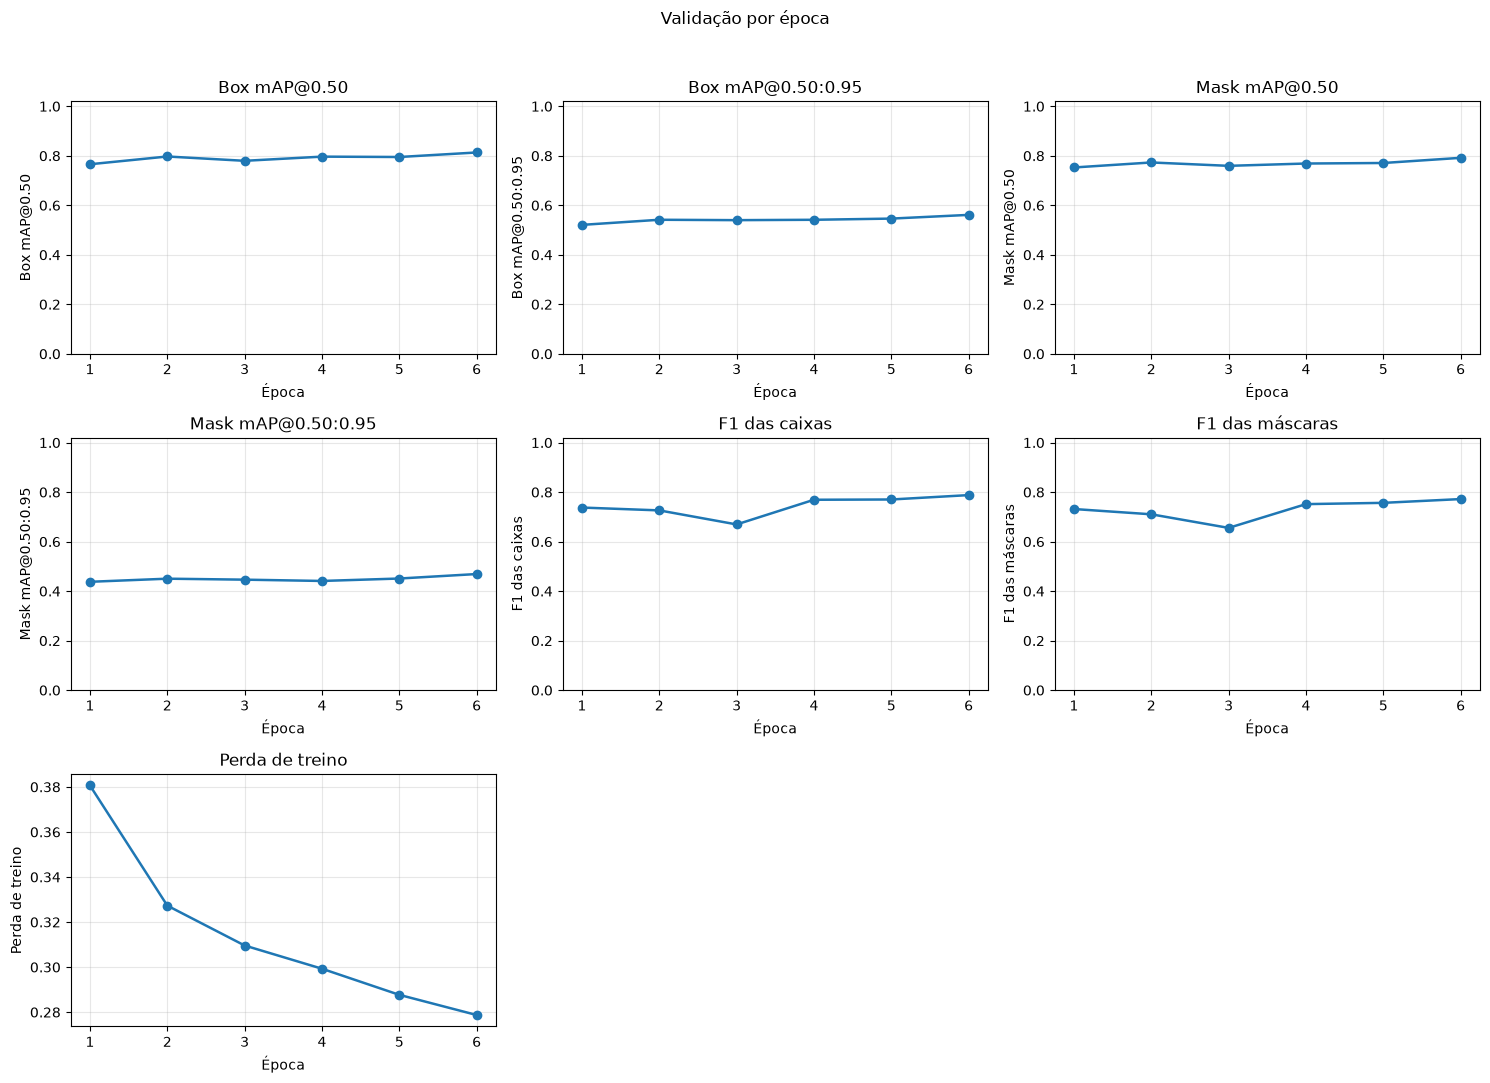

Época 6: perda=0.2787 (máscara=0.1586) | box mAP=0.561 | mask mAP=0.469 | mask F1=0.772


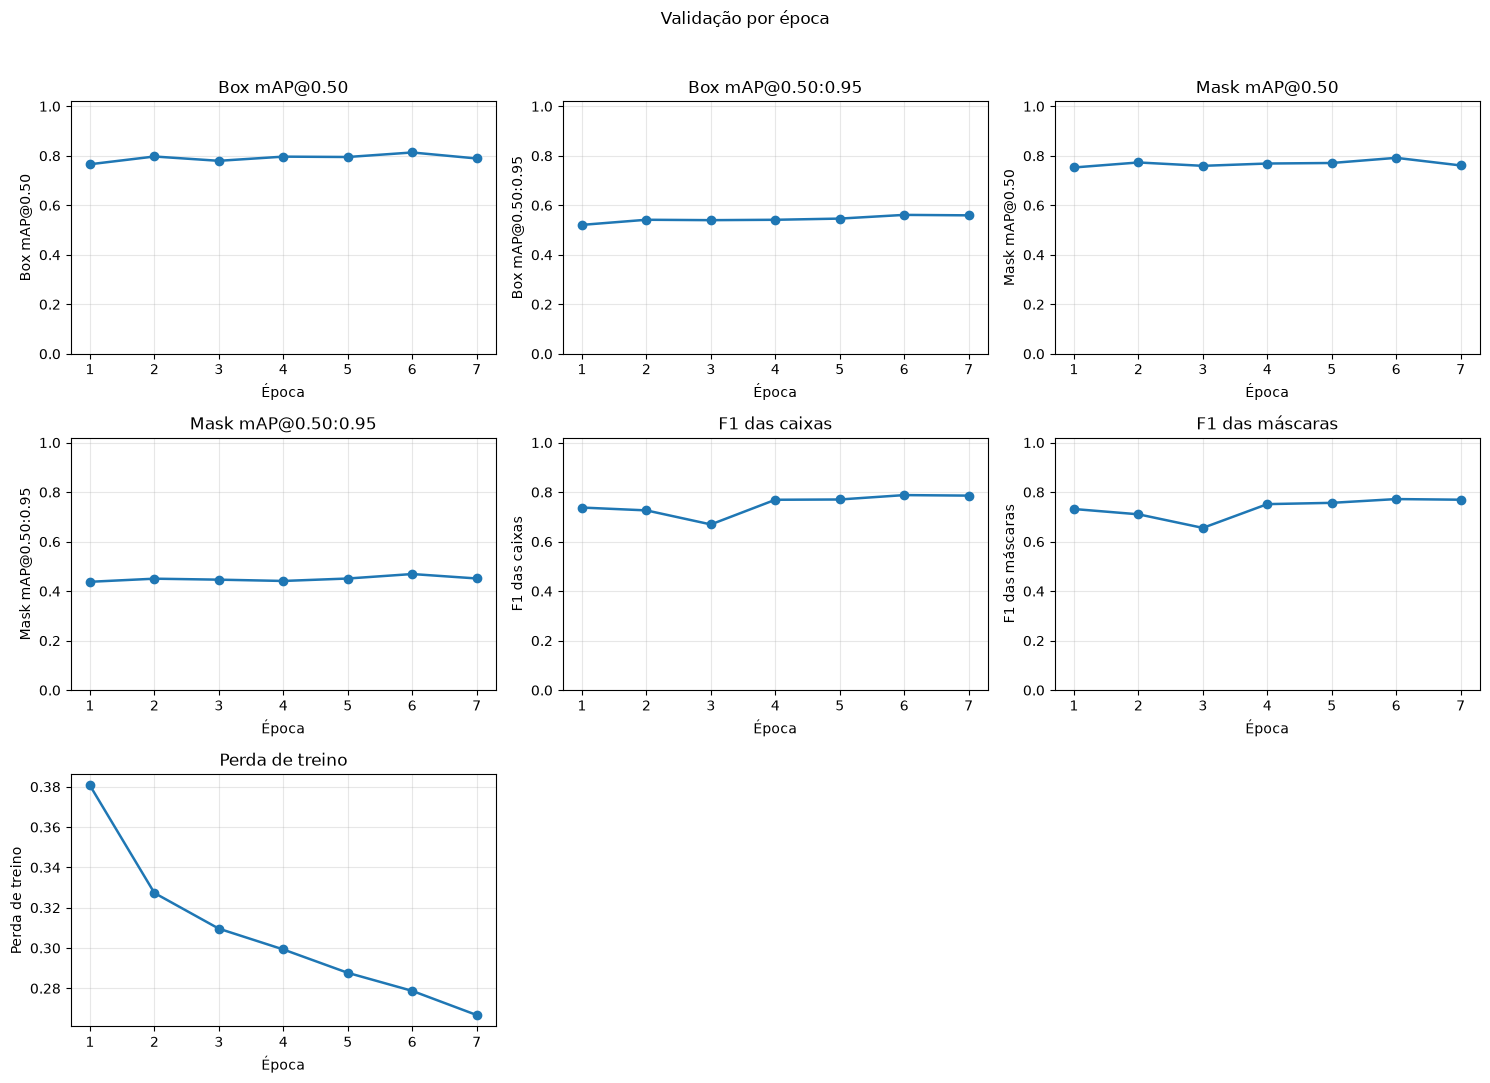

Época 7: perda=0.2668 (máscara=0.1547) | box mAP=0.559 | mask mAP=0.451 | mask F1=0.769


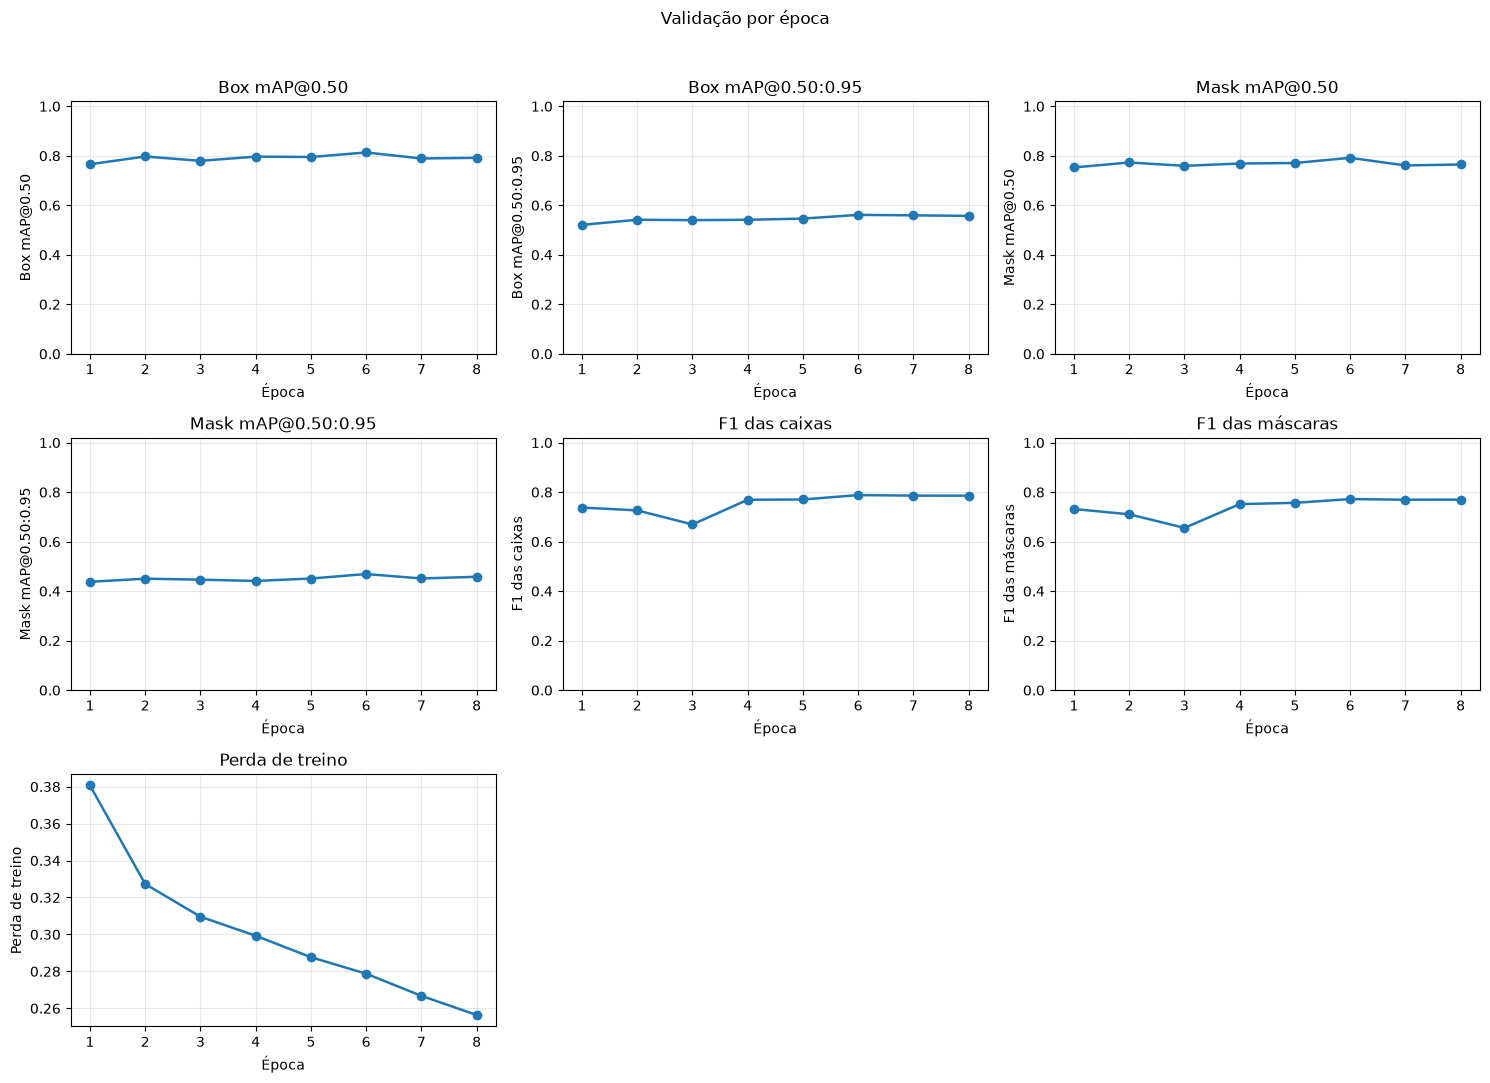

Época 8: perda=0.2564 (máscara=0.1508) | box mAP=0.557 | mask mAP=0.458 | mask F1=0.770


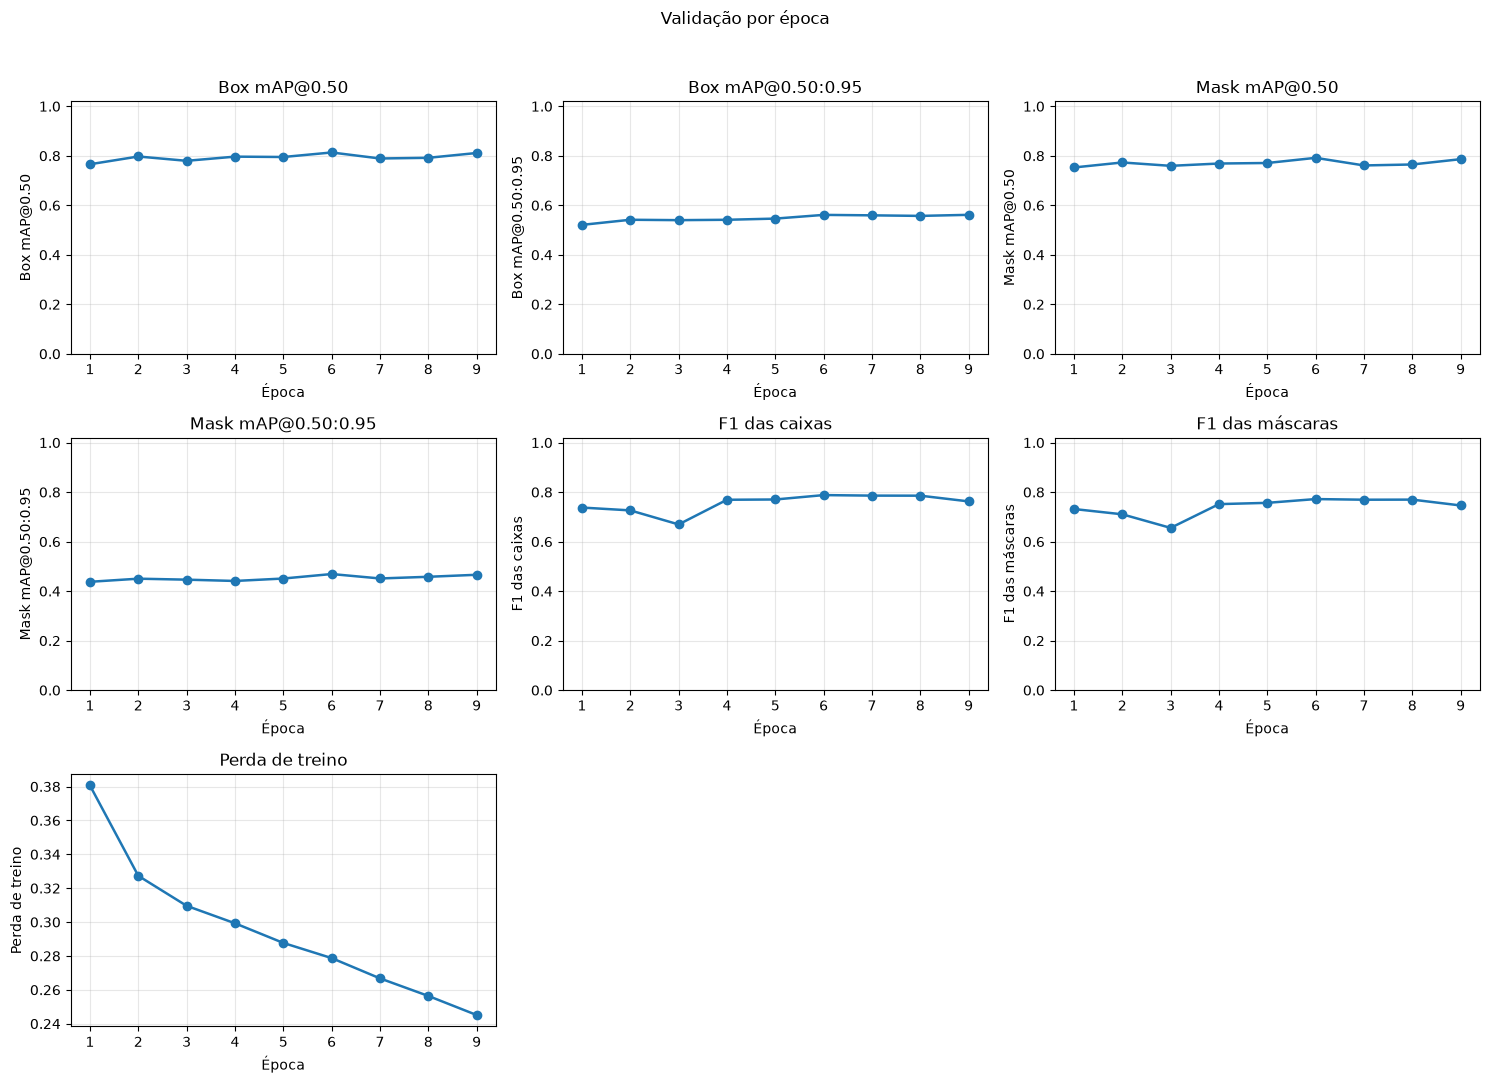

Época 9: perda=0.2451 (máscara=0.1469) | box mAP=0.562 | mask mAP=0.466 | mask F1=0.746


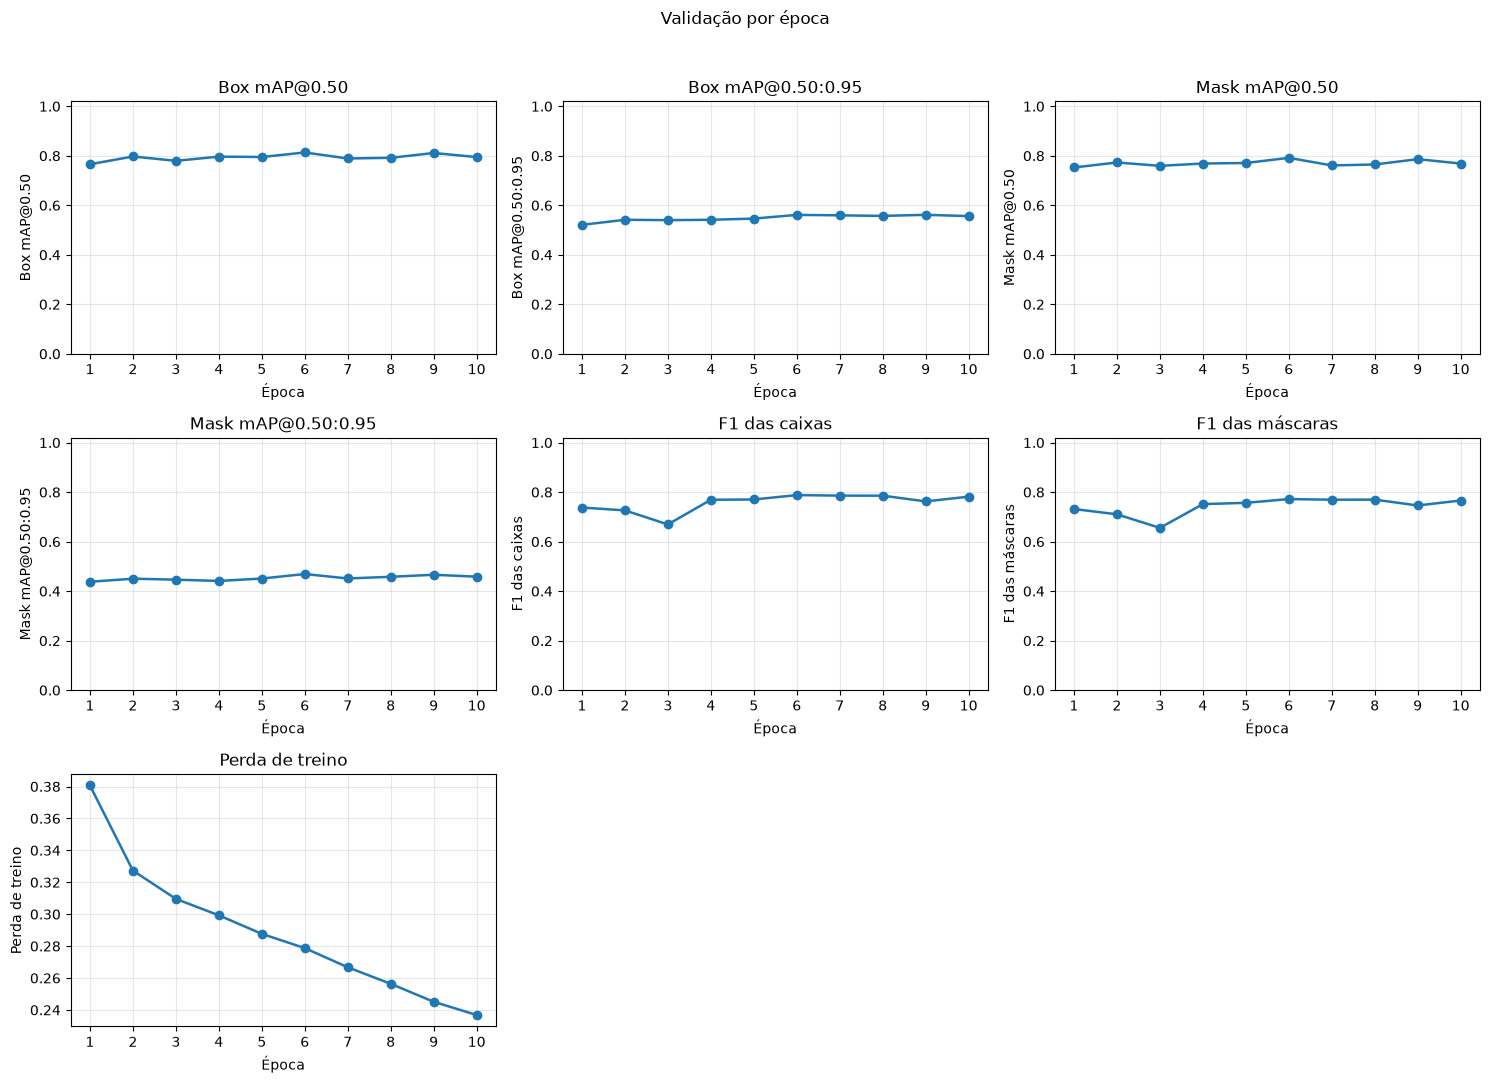

Época 10: perda=0.2368 (máscara=0.1428) | box mAP=0.556 | mask mAP=0.459 | mask F1=0.766


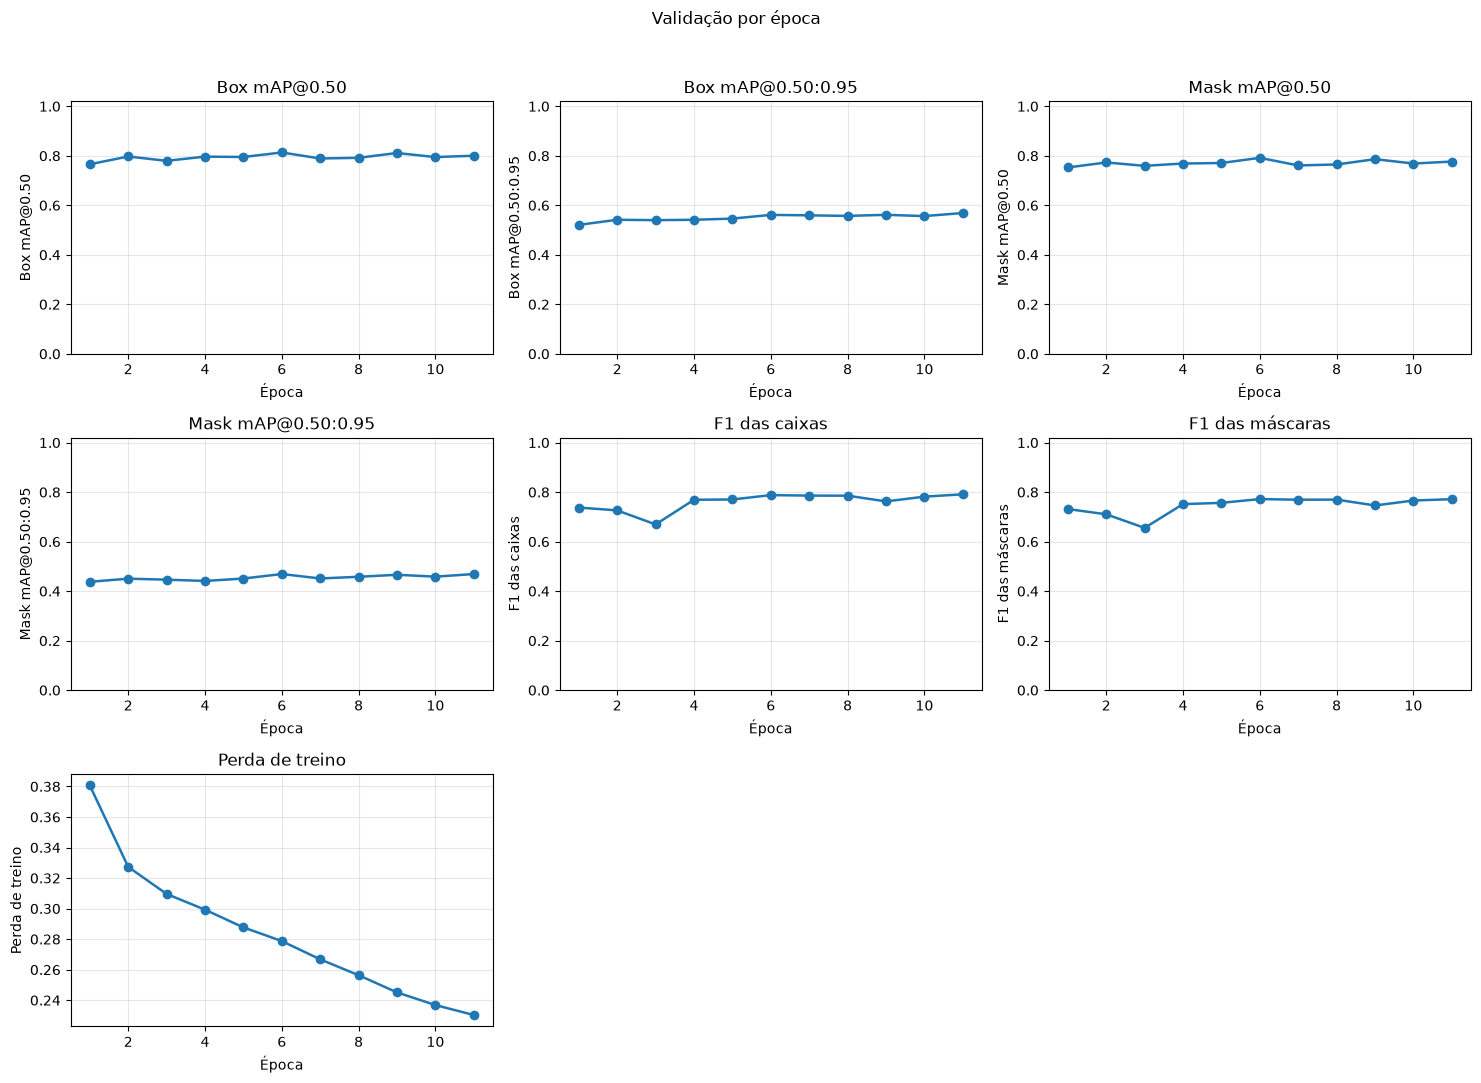

Época 11: perda=0.2303 (máscara=0.1415) | box mAP=0.569 | mask mAP=0.469 | mask F1=0.772


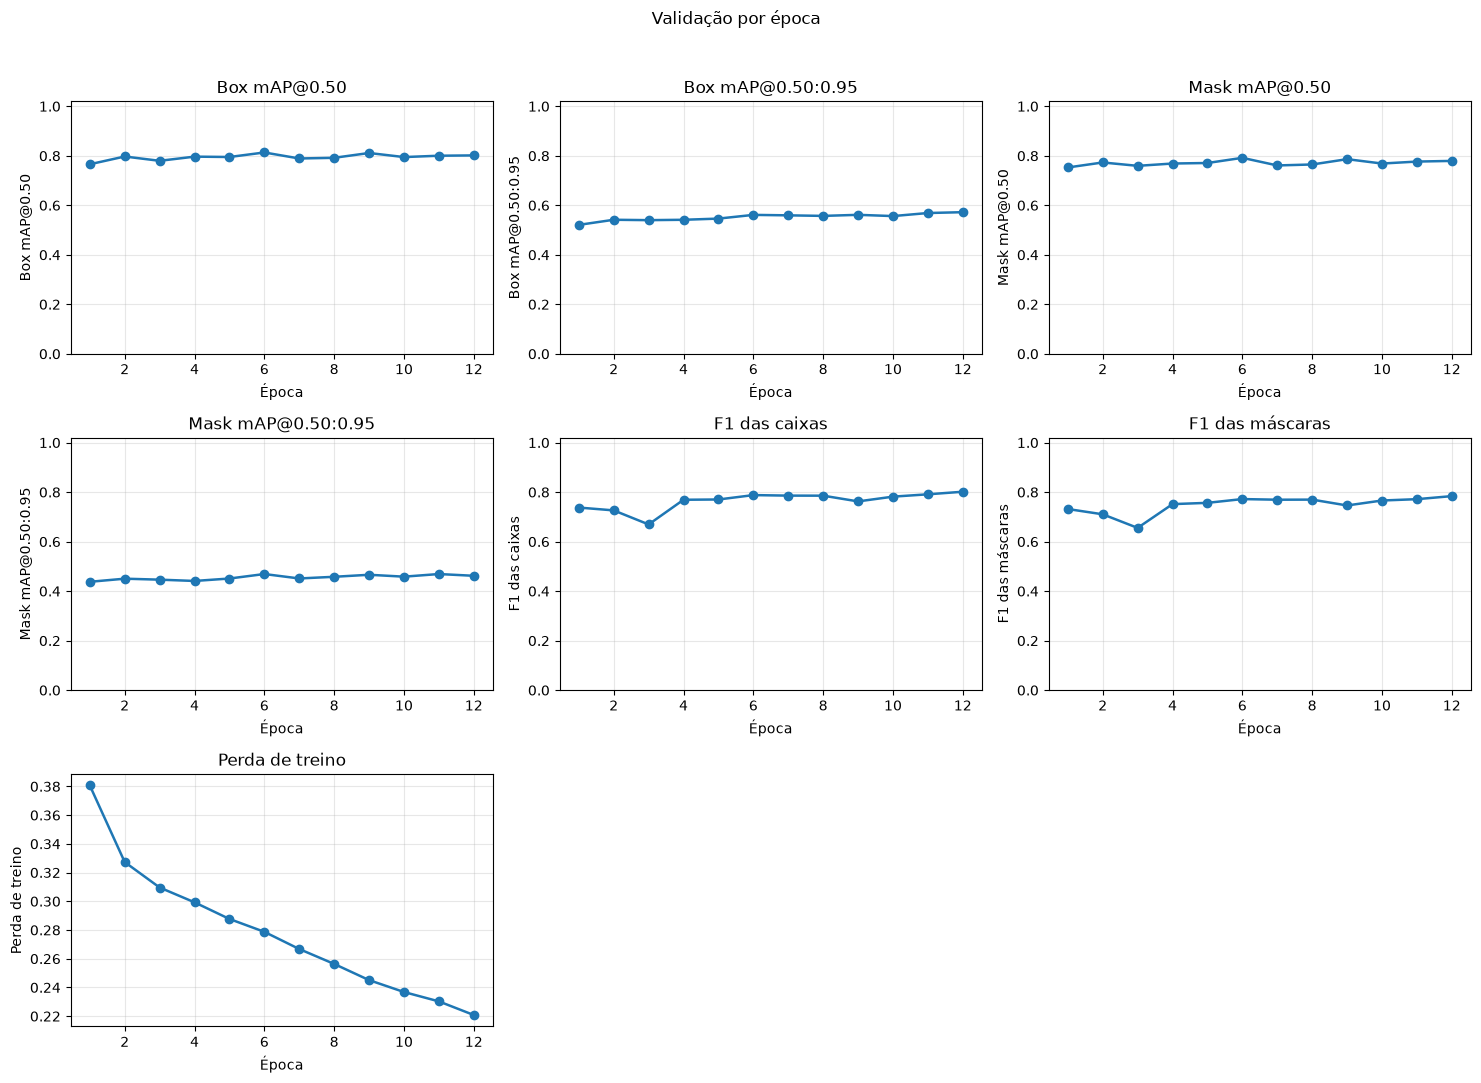

Época 12: perda=0.2208 (máscara=0.1381) | box mAP=0.572 | mask mAP=0.462 | mask F1=0.784


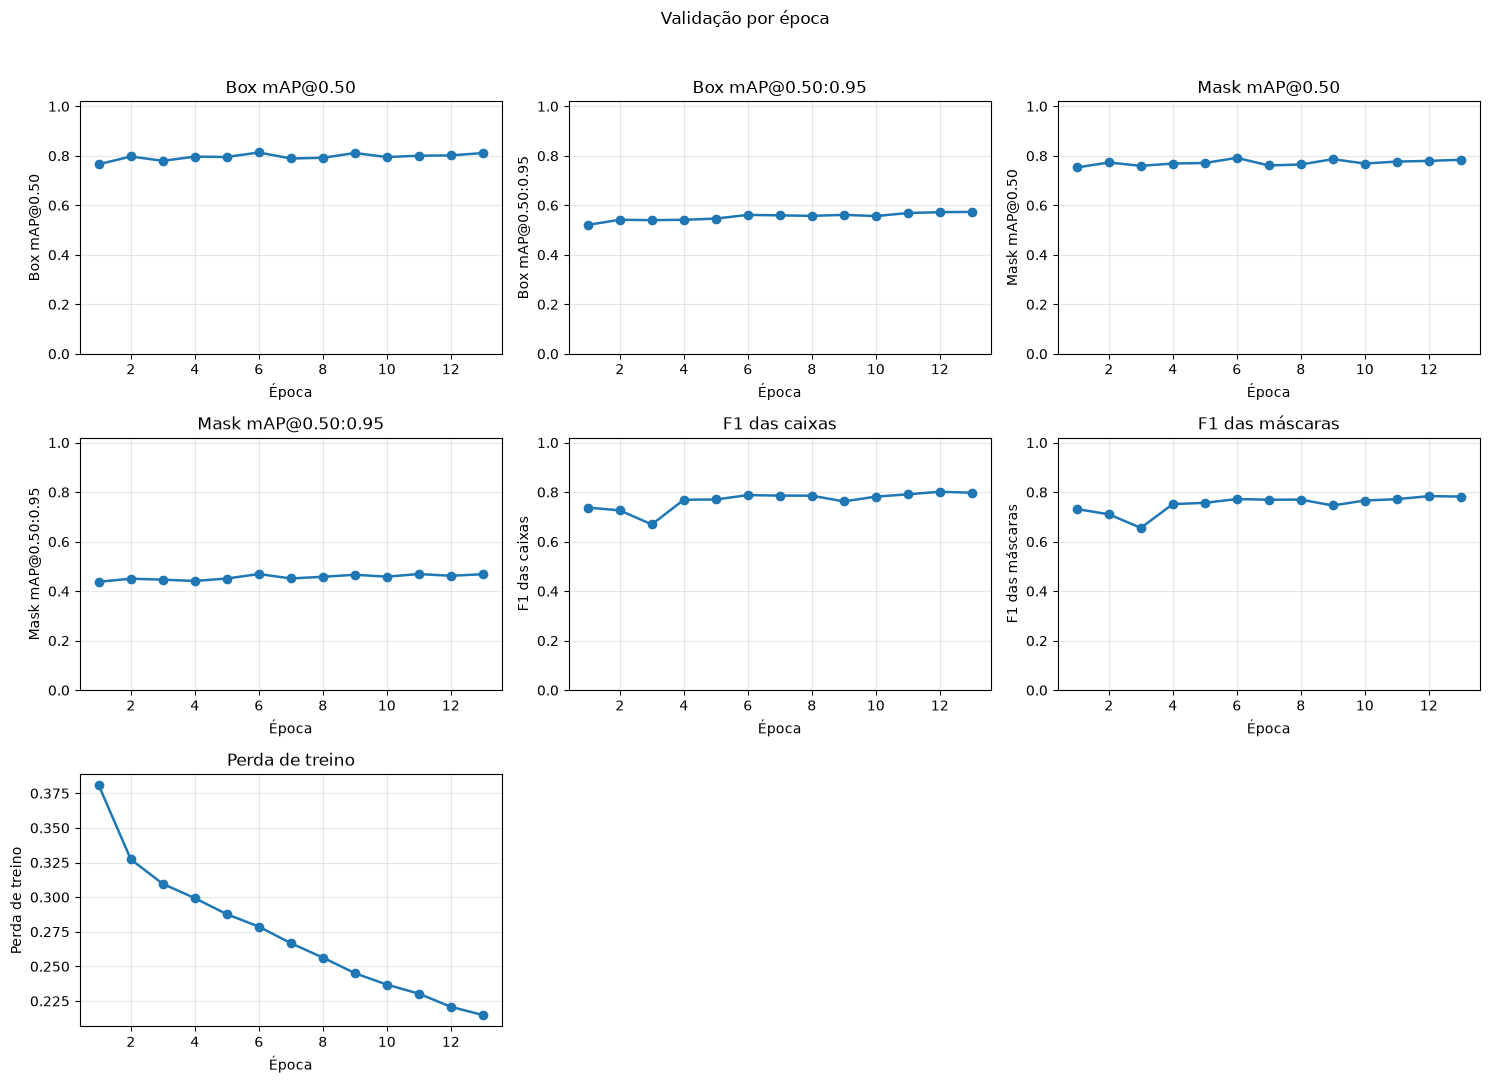

Época 13: perda=0.2149 (máscara=0.1357) | box mAP=0.573 | mask mAP=0.468 | mask F1=0.782


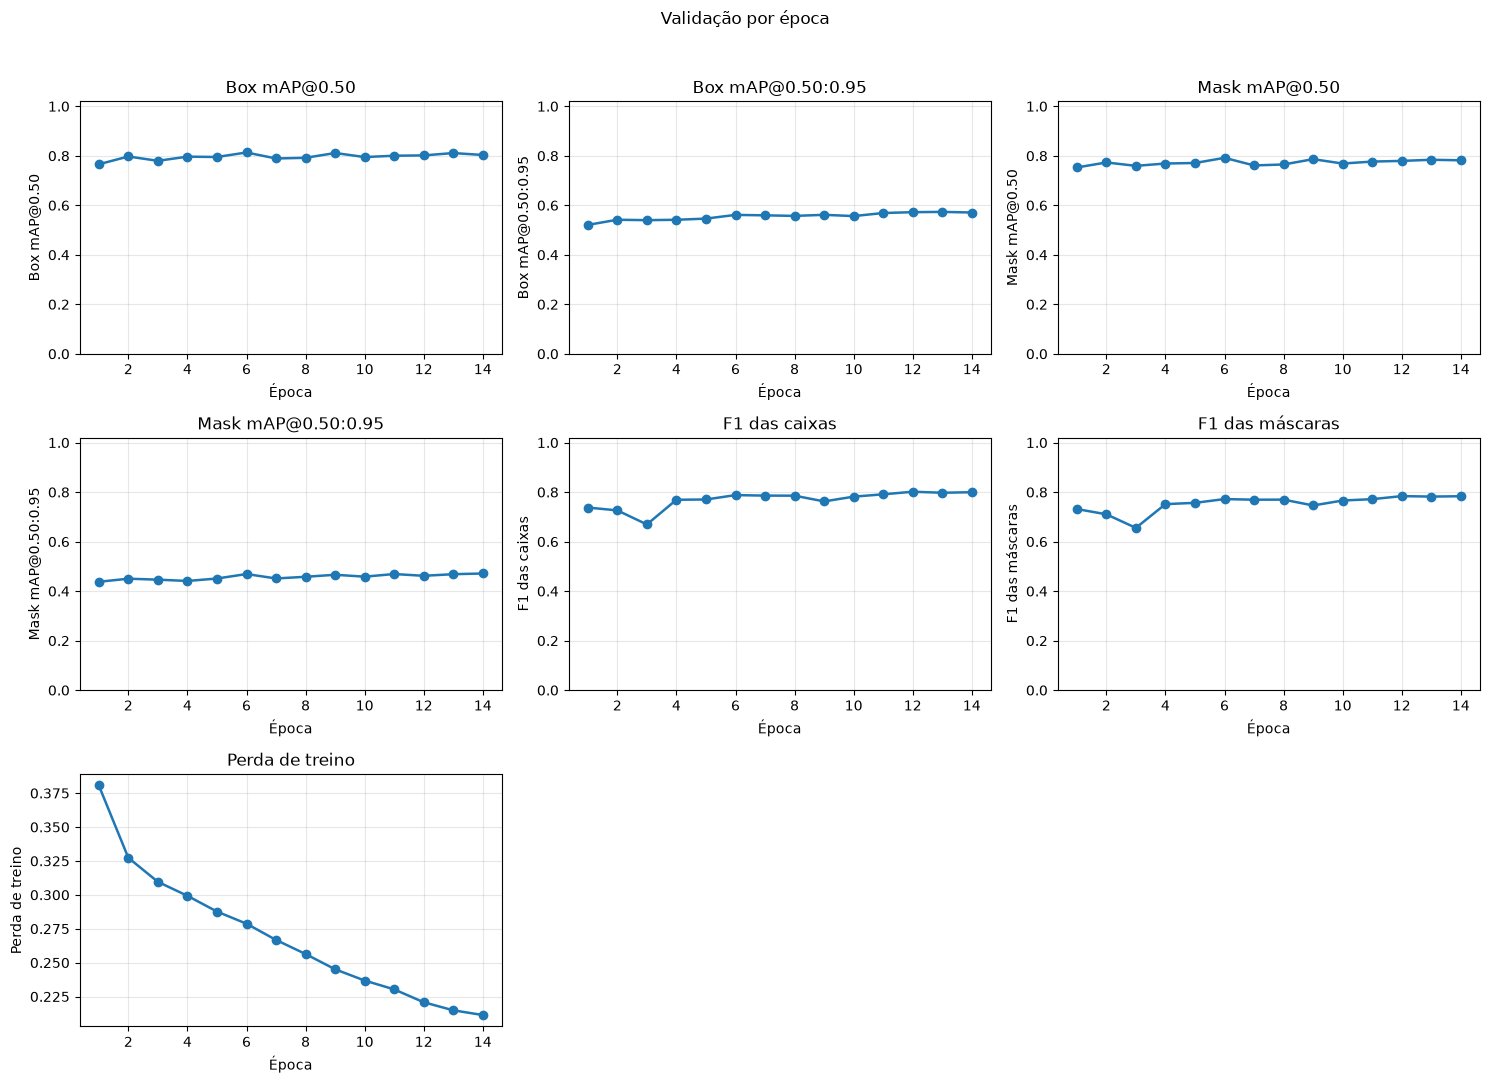

Época 14: perda=0.2114 (máscara=0.1343) | box mAP=0.571 | mask mAP=0.471 | mask F1=0.783


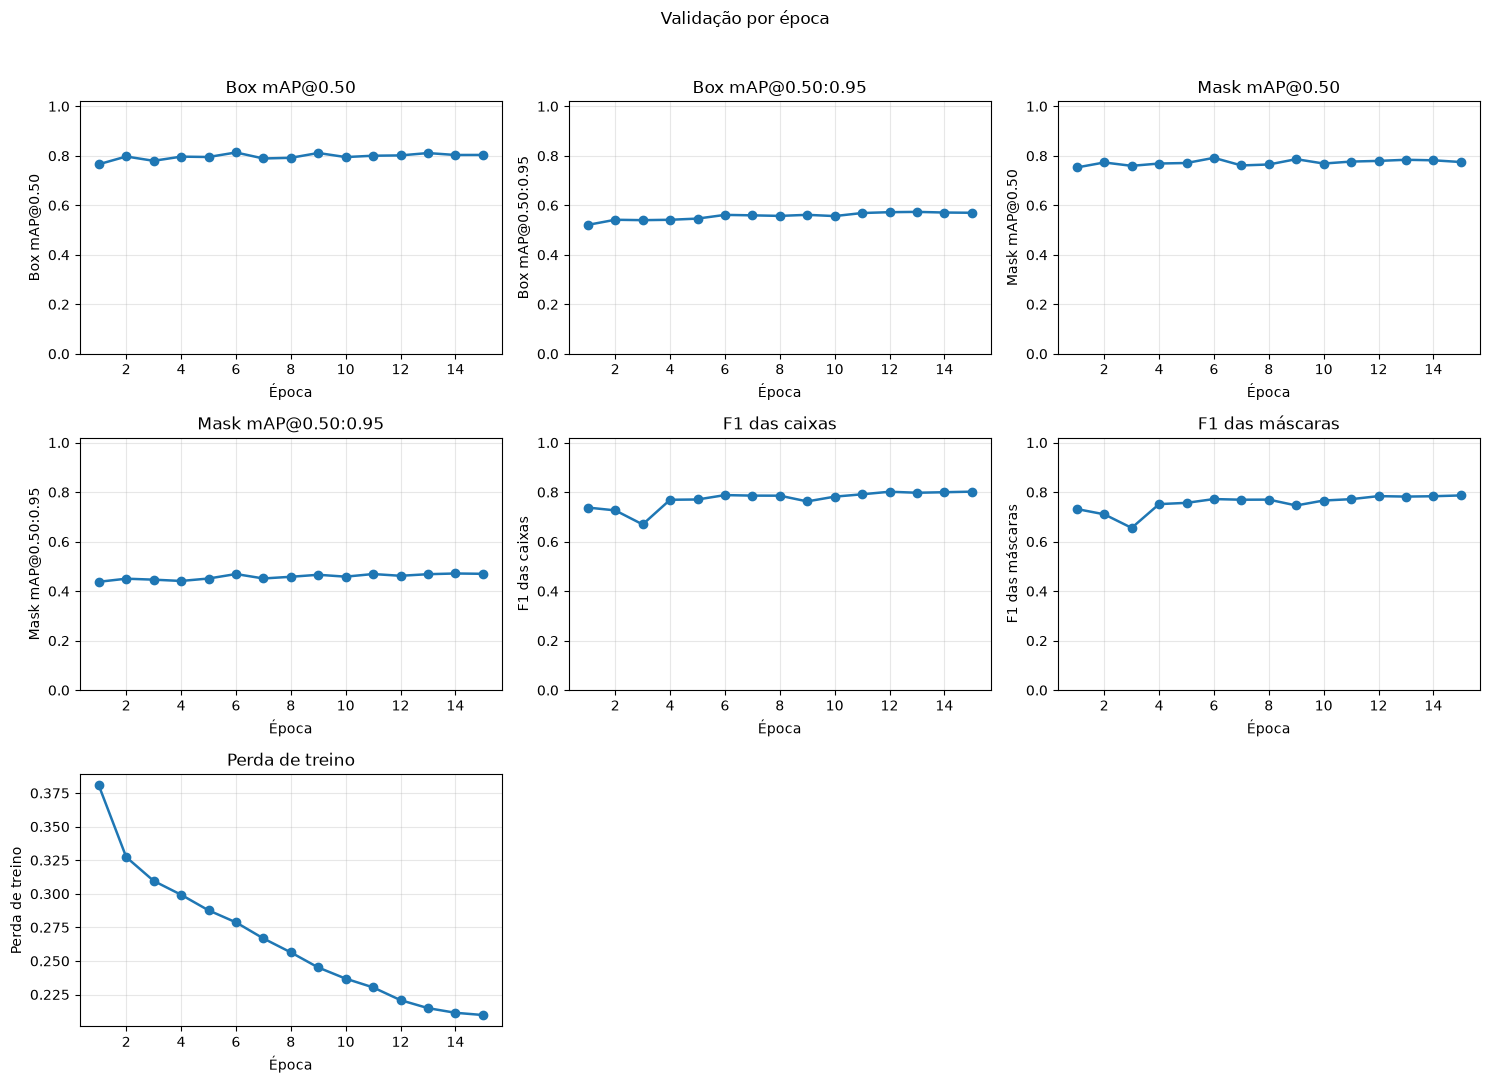

Época 15: perda=0.2097 (máscara=0.1338) | box mAP=0.570 | mask mAP=0.470 | mask F1=0.787
Melhor mask_map_50_95: 0.4713 | checkpoint: /home/miguelherdian/Faculdade_Visao_Computacional/vision-transfer-learning/runs/results/hrsid_mask_rcnn_v2/frozen_backbone/20261108_130031_816248/checkpoints/best.pt


In [27]:
checkpoint = None
if CONFIG['run_training'] or CONFIG['evaluate_test']:
    run_dir = create_run(CONFIG)
    print('Rodada:', run_dir)
    checkpoint = train_experiment(CONFIG, run_dir) if CONFIG['run_training'] else CONFIG['checkpoint_path']

    if CONFIG['evaluate_test']:
        if not checkpoint:
            raise ValueError('Informe checkpoint_path para avaliar um modelo existente')
        best_model, saved = load_checkpoint(checkpoint, DEVICE)
        save_metrics(evaluate(best_model, loaders['test'], DEVICE, CONFIG), run_dir, 'test')
else:
    print('Treinamento e avaliação desativados. Ajuste CONFIG para iniciar uma rodada.')

## 17. Visualização das predições

As figuras comparam, lado a lado, a imagem SAR original, a anotação de verdade e a predição do melhor checkpoint, com uma cor por instância e a confiança escrita acima de cada caixa prevista. Várias embarcações na mesma imagem aparecem como instâncias separadas, que é o ponto da segmentação de instâncias.

O limiar de exibição é `CONFIG['confidence_threshold']`; baixá-lo mostra detecções fracas, subi-lo deixa só as confiantes. As figuras vão para `predictions/` — na pasta da rodada quando o treino acabou de rodar, ou na pasta geral do HRSID quando o checkpoint veio de `CONFIG['checkpoint_path']`.

In [28]:
def draw_prediction(ax, image, boxes, masks, scores=None):
    """Desenha máscaras coloridas por instância e as caixas correspondentes."""
    ax.imshow(image.permute(1, 2, 0).numpy(), cmap='gray')
    if len(masks):
        overlay = np.zeros(masks.shape[1:], dtype=np.int32)
        for index, mask in enumerate(masks.numpy().astype(bool), start=1):
            overlay[mask] = index
        ax.imshow(np.ma.masked_where(overlay == 0, overlay), cmap='tab20', alpha=0.6, interpolation='nearest')
    for index, box in enumerate(boxes.tolist()):
        color = '#ff3b30' if scores is not None else '#34c759'
        ax.add_patch(Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1],
                               fill=False, edgecolor=color, linewidth=1.3))
        if scores is not None:
            ax.text(box[0], max(box[1] - 3, 0), f'{scores[index]:.2f}', color='white', fontsize=7,
                    bbox={'facecolor': color, 'pad': 1})
    ax.axis('off')


def plot_prediction(model, dataset, index, config, device, directory):
    """Imagem original, anotação e predição da mesma imagem SAR."""
    image, target = dataset[index]
    model.eval()
    with torch.no_grad():
        output = model([image.to(device)])[0]
    keep = output['scores'].cpu() >= config['confidence_threshold']
    boxes = output['boxes'].float().cpu()[keep]
    scores = output['scores'].float().cpu()[keep]
    masks = (output['masks'].float().cpu().squeeze(1) >= config['mask_threshold'])[keep]

    file_name = dataset.coco.imgs[dataset.image_ids[index]]['file_name']
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
    axes[0].imshow(image.permute(1, 2, 0).numpy(), cmap='gray')
    axes[0].axis('off')
    axes[0].set_title('Imagem SAR')
    draw_prediction(axes[1], image, target['boxes'], target['masks'])
    axes[1].set_title(f'Anotação — {len(target["boxes"])} navio(s)')
    draw_prediction(axes[2], image, boxes, masks, scores)
    axes[2].set_title(f'Predição — {len(boxes)} navio(s) acima de {config["confidence_threshold"]}')
    fig.suptitle(file_name)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.savefig(directory / f'prediction_{Path(file_name).stem}.png', dpi=150)
    display(fig)
    plt.close(fig)


def show_predictions(model, split, count, config, device, directory):
    """Mostra algumas imagens do split, priorizando as que têm mais navios anotados."""
    directory.mkdir(parents=True, exist_ok=True)
    dataset = datasets[split]
    ranked = sorted(range(len(dataset)),
                    key=lambda index: -len(dataset.coco.getAnnIds(imgIds=dataset.image_ids[index])))
    for index in ranked[:count]:
        plot_prediction(model, dataset, index, config, device, directory)

Checkpoint: /home/miguelherdian/Faculdade_Visao_Computacional/vision-transfer-learning/runs/results/hrsid_mask_rcnn_v2/frozen_backbone/20261108_130031_816248/checkpoints/best.pt | época 14


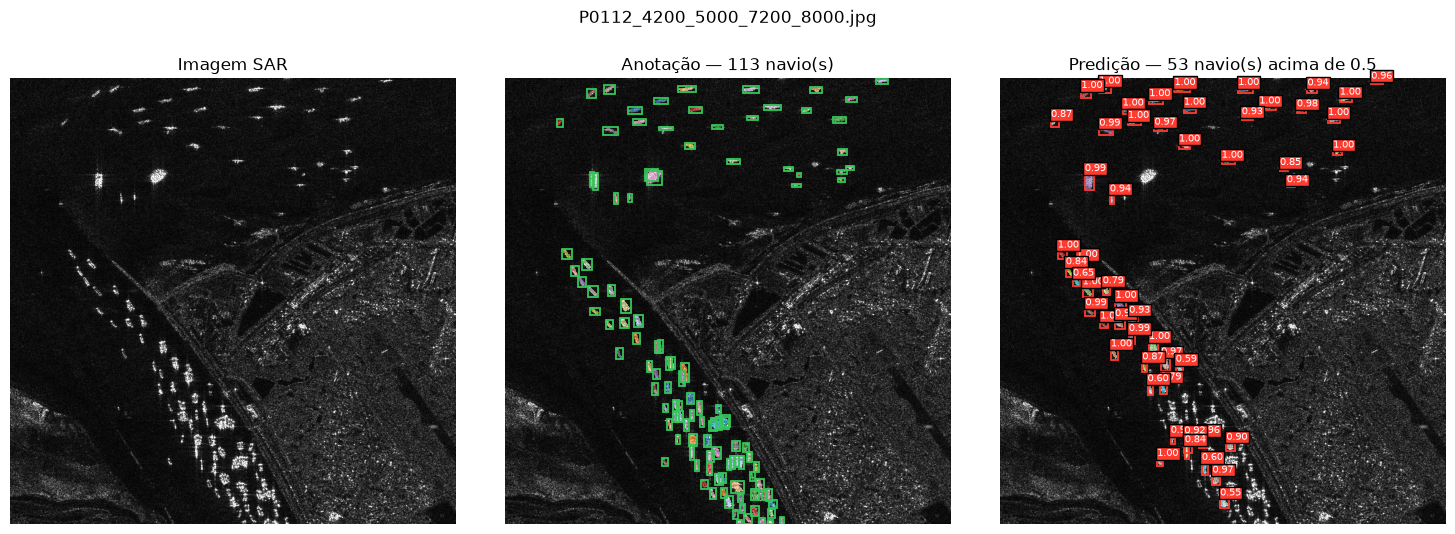

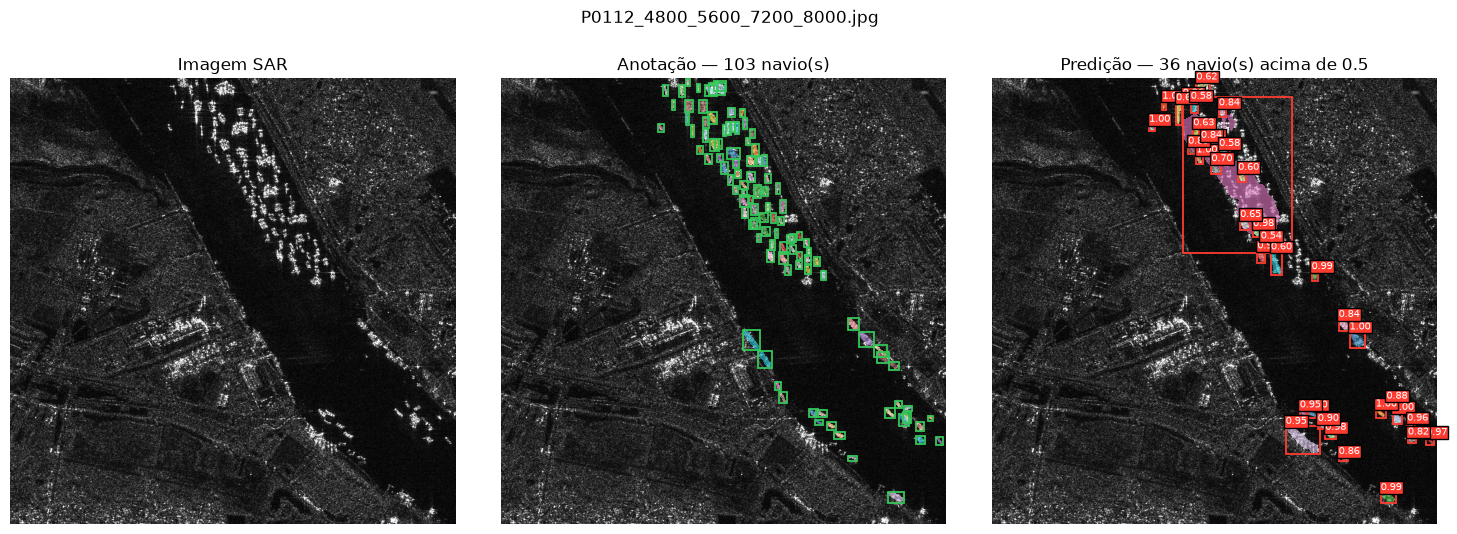

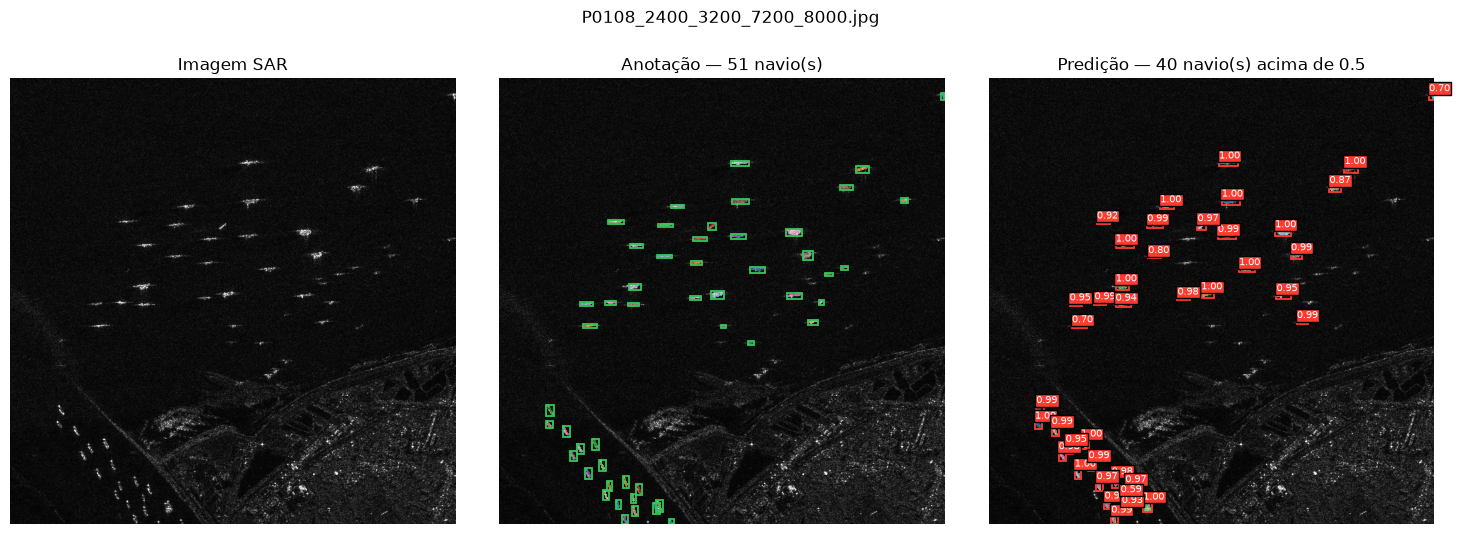

In [29]:
source = checkpoint or CONFIG['checkpoint_path']
if source:
    best_model, saved = load_checkpoint(source, DEVICE)
    directory = (Path(source).parent.parent / 'predictions') if checkpoint else (RESULTS / 'predictions')
    print('Checkpoint:', source, '| época', saved.get('epoch'))
    show_predictions(best_model, 'validation', 3, CONFIG, DEVICE, directory)
else:
    print('Sem checkpoint. Treine uma rodada ou informe CONFIG["checkpoint_path"].')

### Matriz de confusão

Com uma única classe, a matriz de confusão é 2×2: linhas são a verdade (navio ou fundo) e colunas a predição. **TP** é navio casado, **FN** é navio perdido e **FP** é predição sem navio correspondente. O canto fundo × fundo (TN) não existe em detecção — não há como contar "regiões vazias corretamente ignoradas" — e fica em branco. Os limiares são os mesmos da seção 15.

A célula **não treina nem reavalia nada**: lê as contagens já salvas pela rodada — `reports/metrics_test.json` quando o teste foi avaliado, senão as métricas de validação da melhor época guardadas dentro do próprio checkpoint. Basta ter `checkpoint` (rodada recém-treinada) ou `CONFIG['checkpoint_path']` apontando para um `best.pt`.

In [ ]:
def plot_confusion(metrics, tag, directory):
    """Matrizes 2×2 (navio × fundo) de caixas e máscaras a partir de TP, FP e FN."""
    names = ['navio', 'fundo']
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    for ax, (kind, title) in zip(axes, [('box', 'Detecção (caixas)'), ('mask', 'Segmentação (máscaras)')]):
        tp, fp, fn = (int(metrics[f'{kind}_{name}']) for name in ('tp', 'fp', 'fn'))
        matrix = np.array([[tp, fn], [fp, np.nan]], dtype=float)
        ax.imshow(np.ma.masked_invalid(matrix), cmap='Blues', vmin=0)
        ax.set(xticks=range(2), yticks=range(2), xticklabels=names, yticklabels=names,
               xlabel='Predição', ylabel='Verdade', title=title)
        threshold = np.nanmax(matrix) / 2
        for i, j, label in [(0, 0, 'TP'), (0, 1, 'FN'), (1, 0, 'FP')]:
            ax.text(j, i, f'{label}\n{int(matrix[i, j])}', ha='center', va='center',
                    color='white' if matrix[i, j] > threshold else 'black', fontsize=12)
        ax.text(1, 1, 'TN\nnão definido', ha='center', va='center', color='gray', fontsize=10)
    fig.suptitle(f'Matriz de confusão — {tag} (confiança {CONFIG["confidence_threshold"]}, '
                 f'IoU {CONFIG["iou_threshold"]}, máscara {CONFIG["mask_threshold"]})')
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    directory.mkdir(parents=True, exist_ok=True)
    fig.savefig(directory / f'confusion_{tag}.png', dpi=150)
    display(fig)
    plt.close(fig)


source = checkpoint or CONFIG['checkpoint_path']
if source:
    source = Path(source) if Path(source).is_absolute() else ROOT / source
    reports = source.parent.parent / 'reports'
    if (reports / 'metrics_test.json').exists():
        tag, metrics = 'test', json.loads((reports / 'metrics_test.json').read_text(encoding='utf-8'))
    else:
        saved_metrics = torch.load(source, map_location='cpu', weights_only=False)
        tag, metrics = f'validation (época {saved_metrics["epoch"]})', saved_metrics['metrics']
    plot_confusion(metrics, tag.split()[0], source.parent.parent / 'figures')
    print('Fonte das contagens:', tag)
else:
    print('Sem checkpoint. Treine uma rodada ou informe CONFIG["checkpoint_path"].')

## 18. Conclusões e limites

O que este notebook permite afirmar, depois de executar uma rodada:

- Quanto do conhecimento do COCO sobrevive a uma mudança grande de domínio na estratégia escolhida em `CONFIG['experiment']`.
- Quanto a segmentação custa além da detecção, pela diferença entre a mAP de máscara e a de caixa.

Limites que devem acompanhar qualquer leitura dos números:

- **O teste é usado uma vez.** Toda escolha de época, limiar e estratégia vem da validação. Se o teste oficial for avaliado várias vezes com ajustes no meio, ele deixa de ser teste.
- **A validação sai do treino oficial**, separada por cena para evitar vazamento entre recortes vizinhos. Ainda assim, cenas diferentes do mesmo satélite e da mesma região se parecem; o resultado não mede generalização para outro sensor.
- **O teste oficial compartilha cenas com o treino.** A seção 6 imprime quantas. Quando esse número é alto, o teste mede acerto em recortes novos das mesmas cenas, não em cenas novas — e a validação por cena deste notebook passa a ser o único conjunto realmente separado do que foi treinado.
- **As contagens oficiais nem sempre fecham entre si.** O número publicado de 16.951 navios corresponde ao arquivo combinado `train_test2017.json`; somar `train2017.json` e `test2017.json` pode dar um total diferente. O notebook relata o que contou nos arquivos que usou, e é esse número que vale para o modelo treinado.
- **Precisão, recall e F1 dependem dos limiares** de confiança, de IoU e de máscara declarados na seção 15. A mAP não depende da confiança, mas segue o protocolo COCO, que pode não coincidir com o usado no artigo original do HRSID — comparações diretas com a literatura exigem conferir o protocolo.
- **Navios pequenos dominam o dataset**, e o próprio protocolo COCO penaliza erros de poucos pixels neles com mais força. A mAP geral esconde essa diferença; `map_small` e `map_large` do `torchmetrics` ajudam a separar.
- **Inshore e offshore são muito diferentes.** Navios atracados perto da costa se confundem com estruturas em terra; o HRSID distribui listas separadas para esses regimes, e uma avaliação por regime diria mais do que um único número.
- **Uma rodada não é uma medida.** Com uma só semente, parte do resultado é ruído. Repetir com sementes diferentes dá a variação natural.